# Brain-age research summary: cohorts, experiments, the best model and what mattered

📄 **[PDF version of this notebook](brain_age_research_summary.pdf)** (figures, tables and formulas, no
code; regenerate with `scripts/notebook_to_pdf.py notebooks/brain_age_research_summary.ipynb`).

One notebook for the whole EEG brain-age study on TUH (2026-10-05 → 10-16), in three phases:

* **Phase 1, TUAB only.** About 50 fine-tunes of LaBraM-base on the TUH Abnormal corpus (TUAB), aimed at
  memorization: schedule, regularizers, mixup/EMA, loss shape, codebook regularization, heads, training
  from scratch (`docs/age_overfitting_experiments.md`).
* **Phase 2, full TUH.** The same recipe on cohorts drawn from the whole TUH EEG corpus (TUEG, about
  60k recordings), plus data, input and head changes (`docs/data/tuh_cohort_eval_v1.csv`).
* **Phase 3, cross-validation.** 5-fold patient-grouped CV of the three strongest phase-2 configurations
  (`notebooks/tuh_cv_summary.ipynb`, `docs/data/cv5_eval_v2.csv`).

It answers four questions:
1. Which datasets and cohorts were used, and how they differ (Section 1).
2. Which experiments ran and which came out near the best (Section 2).
3. What exactly the best experiment does, step by step (Section 3).
4. What changed relative to LaBraM as published (Section 4), and which of those changes measurably
   moved the error (Section 5).

**Contents.** 0 Metrics and evaluation sets · 1 Data · 2 Experiments · 3 The best experiment ·
4 Changes versus the LaBraM recipe · 5 Which changes mattered · 6 Conclusions.

**Inputs.**
* In git: the registry, the two CSVs, `docs/data/line_removal_ab.json`, the configs,
  `docs/data/brain_age_clearml_runs.csv` (each run's ClearML experiment) and
  `scripts/submit_tuh_cohorts.sh`. Every phase-2 run's configuration is rebuilt from
  `labram/eval/research_summary.py::PHASE2` with the same config loader the trainer uses.
  `tests/test_research_summary.py` checks that catalog against the submit script.
* Optional, on the TUH data volume (`LABRAM_TUH_ROOT`, default `/data/datasets/EEG-public/TUH_EEG`):
  * the cohort manifests behind Section 1's counts;
  * the TUH recording index and NEDC's clinical sheet behind the TUEG specification (Tables 1.3–1.6);
  * the per-recording CV predictions behind the bootstraps (`LABRAM_CV_EVAL`).

  They stay out of git under the TUH data-use agreement. Without them those cells print a note and skip,
  and the outputs show only aggregate counts.

## 0. Metrics and evaluation sets

Every error is computed **per recording**. A recording's predicted age is the mean of its window
predictions (Eq. (3.7)), in years. For a set $S$ of recordings with true age $y_i$ and predicted age
$\hat y_i$:

$$ \mathrm{MAE}(S) = \frac{1}{|S|}\sum_{i\in S}\lvert \hat y_i - y_i\rvert \tag{0.1} $$

$$ R^2(S) = 1 - \frac{\sum_{i\in S}(\hat y_i - y_i)^2}{\sum_{i\in S}(y_i - \bar y_S)^2} \tag{0.2} $$

$$ \mathrm{bias}(S) = \frac{1}{|S|}\sum_{i\in S}(\hat y_i - y_i) \tag{0.3} $$

where $\bar y_S$ is the mean true age of $S$ (`labram/eval/cv_compare.py::metrics`). The effect of a
change from a baseline run $b$ to a variant run $v$ is

$$ \Delta\mathrm{MAE} = \mathrm{MAE}_v(S) - \mathrm{MAE}_b(S), \tag{0.4} $$

so **negative is better**. Section 5 defines when a $\Delta$ is larger than run-to-run noise.

**All errors are before bias correction.** Every MAE in this notebook scores the raw prediction
$\hat y_i$. The only exception is Table 3.5, which compares raw and bias-corrected errors.

The **bias slope** $\beta$ measures regression to the mean, the typical failure of an age model: old
patients are predicted too young and young ones too old. It is the least-squares slope of the error
$e_i = \hat y_i - y_i$ against the true age, with population moments over $S$
(`labram/utils/regression_metrics.py`, `age_bias_slope`):

$$ \beta(S) = \frac{\operatorname{Cov}_S(y, e)}{\operatorname{Var}_S(y)} \tag{0.5} $$

* $\beta = 0$: the error does not depend on age.
* $\beta = -1$: the prediction ignores age entirely; it is a constant.
* $\beta = -0.4$: a patient 10 years older than average is predicted about 4 years too young.

**Evaluation sets.**
* **TUAB test:** TUAB's official evaluation set, 274 recordings of 251 patients (149 normal, 125
  abnormal). It is the same 274 recordings in every phase (checked in Section 1) and no training split
  contains any of its patients, so it is the one yardstick every run shares.
* **Val:** each run's own validation split. It differs between cohorts, so it compares runs only within
  a cohort.
* **CV test / TUEG out-of-fold:** each recording of the CV pool scored by the one fold model that never
  saw its patient.

**Caveat.** Phases 1 and 2 compared many configurations on the TUAB test set, which makes their
best single-split numbers optimistically selected. The CV numbers (Phase 3) and the TUEG out-of-fold
error were not used to choose anything.

In [1]:
import json
import os
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

if not any(os.path.isdir(os.path.join(p, "labram")) for p in sys.path):
    sys.path.insert(0, os.path.abspath(".."))
REPO = next(p for p in sys.path if os.path.isdir(os.path.join(p, "labram")))
warnings.filterwarnings("ignore")
from labram.eval import research_summary as rs
from labram.eval import cv_compare as cc
from labram.eval.age_plots import assert_max_columns, numbered_table, panel_labels

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 90)

AGE_JSON = os.path.join(REPO, "labram/configs/defaults/finetune_tuab_age.json")
PAPER_JSON = os.path.join(REPO, "labram/configs/defaults/finetune_tuab_paper.json")
REGISTRY = os.path.join(REPO, "docs/age_overfitting_experiments.md")
COHORT_CSV = os.path.join(REPO, "docs/data/tuh_cohort_eval_v1.csv")
CV_CSV = os.path.join(REPO, "docs/data/cv5_eval_v2.csv")
AB_JSON = os.path.join(REPO, "docs/data/line_removal_ab.json")
CLEARML_CSV = os.path.join(REPO, "docs/data/brain_age_clearml_runs.csv")
SPLITS_CSV = os.path.join(REPO, "docs/data/brain_age_run_splits.csv")
TUH = os.environ.get("LABRAM_TUH_ROOT", "/data/datasets/EEG-public/TUH_EEG")
CV_PREDS = os.path.join(os.environ.get("LABRAM_CV_EVAL", os.path.join(TUH, "_state/cohort_runs/cv_eval")),
                        "cv_preds.json")
HAVE_TUH = os.path.isdir(os.path.join(TUH, "cohorts"))
HAVE_PREDS = os.path.exists(CV_PREDS)

reg = rs.registry_master_table(REGISTRY)
cml = rs.load_clearml_runs(CLEARML_CSV)      # run -> ClearML experiment name and link
run_splits = pd.read_csv(SPLITS_CSV)          # run x split -> recordings, patients, windows, digest
split_sig = rs.split_signature(run_splits)    # run -> train/val/test recording digests
coh = pd.read_csv(COHORT_CSV)
cv = pd.read_csv(CV_CSV)
print(f"registry: {len(reg)} phase-1 runs; cohort CSV: {coh.model.nunique()} phase-2 runs; "
      f"CV CSV: {cv.exp.nunique()} experiments x {cv.fold.nunique()} folds")
print(f"TUH data volume: {'found' if HAVE_TUH else 'not found (Section 1 counts skipped)'}; "
      f"per-recording CV predictions: {'found' if HAVE_PREDS else 'not found (bootstraps skipped)'}")

registry: 45 phase-1 runs; cohort CSV: 19 phase-2 runs; CV CSV: 3 experiments x 5 folds
TUH data volume: found; per-recording CV predictions: found


## 1. Data: every dataset and cohort

All data comes from the TUH EEG corpus. TUAB (TUH Abnormal, about 3k recordings with a normal/abnormal
label) is a subset of TUEG (the full TUH EEG corpus, about 60k recordings). The age label is parsed from
each EDF header (`labram/data/tuh_metadata.py`). Every dataset uses the same signal format:
* 23 referential channels at 200 Hz in µV, 0.1–75 Hz band-pass;
* 10 s windows;
* the first and last 60 s of each recording dropped;
* evaluation on the first 5 minutes after the trim (`labram/data/window_selection.py`).

The datasets differ in which recordings they contain, how mains interference is removed, and how
patients are split.

**Lineage.**
* `TUAB v3.0.0` (phase 1) → `TUAB v3.0.1 interp` (phase-2 control): same recordings and split, mains
  removed by 50 + 60 Hz spectrum interpolation instead of a 50 Hz notch.
* `normal_tueg_v1`, `normal_both_v1`: normal recordings only (TUEG alone; TUAB + TUEG).
* `all_both_v1` → `v2` → `v3`: every recording (normal, abnormal, unlabelled), with TUAB patients kept
  in their TUAB split.
  * `v2` gives TUEG one patient split shared by every cohort, so validation is comparable across
    cohorts.
  * `v3` adds the TUEG recordings that lack only the T1/T2 electrodes.
* `v3_compact` / `v3_cvcompact`: byte-for-byte subsets of `v3` that store only the windows a run reads
  (`dataset_maker/make_compact_cohort.py`). `cvcompact` keeps both training and evaluation windows of
  every recording, so any CV fold can use any recording.

Tables 1.3–1.6 and Figure 1.2 at the end of this section specify TUEG itself: size, subsets, labels
and age.

All cohorts are built by `dataset_maker/make_cohort_dataset.py`, which drops every TUEG recording of a
TUAB-test patient and asserts that no patient is in two splits.

### Table 1.1. Datasets and cohorts

One row per dataset.

| column | meaning |
|---|---|
| `phase` | the phase that used the dataset |
| `contents` | which recordings it holds |
| `line removal` | how mains interference is removed (from the dataset's `manifest.json`) |
| `rules` | inclusion rules: `age` range in years; `≥ min` minimum recording length in minutes; `≤ k/patient` at most *k* train/val recordings per patient; `T1/T2 may be missing` |
| `TUEG split` | how TUEG patients are split; TUAB patients always keep their TUAB split |
| `used by` | the runs of Tables 2.2–2.4 trained on it |

In [2]:
DATASETS = [
    ("TUAB v3.0.0", "1", "tuab/v3.0.1/edf/legacy_v3.0.0_processed", "TUAB, all recordings (normal + abnormal)",
     "phase-1 runs (Table 2.2)"),
    ("TUAB v3.0.1 interp", "2", "tuab/v3.0.1/edf/processed_npy_interp50-60", "TUAB, all recordings", "Control"),
    ("normal_tueg_v1", "2", "cohorts/normal_tueg_v1", "TUEG normal, patients outside TUAB; no test split", "Exp2"),
    ("normal_both_v1", "2", "cohorts/normal_both_v1", "TUAB normal + TUEG normal", "Exp1, Exp1b, Exp1t, Exp1f"),
    ("all_both_v1", "2", "cohorts/all_both_v1", "TUAB + TUEG, every recording (normal / abnormal / no label)",
     "Exp3, Exp3b, Exp3q, Exp3c"),
    ("all_both_v2", "2", "cohorts/all_both_v2", "as v1, TUEG patients on the shared split",
     "Exp3v2, Exp3cond, Exp3clscond"),
    ("all_both_v3", "2", "cohorts/all_both_v3", "v2 + TUEG recordings missing only T1/T2",
     "Exp4drop, Exp4base, Exp4ctrl, Exp4aug, Exp4aug15"),
    ("all_both_v3_compact", "2", "cohorts/all_both_v3_compact", "v3, only the windows Exp4base reads", "Exp4basec"),
    ("all_both_v3_cvcompact", "3", "cohorts/all_both_v3_cvcompact",
     "v3, training + evaluation windows of every recording (CV pool = train + val)", "cvbase, cvctrl, cvaug"),
]


def manifest(path):
    p = os.path.join(TUH, path, "manifest.json")
    return json.load(open(p)) if os.path.exists(p) else {}


def rules(m):
    c = m.get("cohort", {})
    if not c:
        return "age 1–89 (TUAB)"
    r = [f"age {c['min_age']}–{c['max_age']}", f"≥ {c['min_minutes']:g} min", f"≤ {c['max_per_subject']}/patient"]
    if c.get("allow_missing"):
        r.append("/".join(c["allow_missing"]) + " may be missing")
    return ", ".join(r)


rows = []
for name, phase, path, contents, used in DATASETS:
    m = manifest(path) if HAVE_TUH else {}
    lr = m.get("line_removal") or ("notch:50" if "legacy" in path else "–")
    c = m.get("cohort", {})
    split = ("shared patient split v2" if c.get("patient_split") else
             ("seeded 10 % val" if c else "TUAB: seeded 20 % val, official test"))
    rows.append({"dataset": name, "phase": phase, "contents": contents, "line removal": lr,
                 "rules": rules(m) if HAVE_TUH else "–", "TUEG split": split, "used by": used})
table_1_1 = pd.DataFrame(rows)
numbered_table(table_1_1.set_index("dataset"), "1.1", "Datasets and cohorts")

,phase,contents,line removal,rules,TUEG split,used by
dataset,,,,,,
TUAB v3.0.0,1,"TUAB, all recordings (normal + abnormal)",notch:50,age 1–89 (TUAB),"TUAB: seeded 20 % val, official test",phase-1 runs (Table 2.2)
TUAB v3.0.1 interp,2,"TUAB, all recordings","interp:50,60",age 1–89 (TUAB),"TUAB: seeded 20 % val, official test",Control
normal_tueg_v1,2,"TUEG normal, patients outside TUAB; no test split","interp:50,60","age 18–89, ≥ 5 min, ≤ 10/patient",seeded 10 % val,Exp2
normal_both_v1,2,TUAB normal + TUEG normal,"interp:50,60","age 18–89, ≥ 5 min, ≤ 10/patient",seeded 10 % val,"Exp1, Exp1b, Exp1t, Exp1f"
all_both_v1,2,"TUAB + TUEG, every recording (normal / abnormal / no label)","interp:50,60","age 18–89, ≥ 5 min, ≤ 10/patient",seeded 10 % val,"Exp3, Exp3b, Exp3q, Exp3c"
all_both_v2,2,"as v1, TUEG patients on the shared split","interp:50,60","age 18–89, ≥ 5 min, ≤ 10/patient",shared patient split v2,"Exp3v2, Exp3cond, Exp3clscond"
all_both_v3,2,v2 + TUEG recordings missing only T1/T2,"interp:50,60","age 18–89, ≥ 5 min, ≤ 10/patient, T1/T2 may be missing",shared patient split v2,"Exp4drop, Exp4base, Exp4ctrl, Exp4aug, Exp4aug15"
all_both_v3_compact,2,"v3, only the windows Exp4base reads","interp:50,60","age 18–89, ≥ 5 min, ≤ 10/patient, T1/T2 may be missing",shared patient split v2,Exp4basec
all_both_v3_cvcompact,3,"v3, training + evaluation windows of every recording (CV pool = train + val)","interp:50,60","age 18–89, ≥ 5 min, ≤ 10/patient, T1/T2 may be missing",shared patient split v2,"cvbase, cvctrl, cvaug"


### Table 1.2. Size and composition per split

For each dataset and split:
* `recordings` and `patients`;
* `from TUAB`: recordings that are also in TUAB;
* `normal` / `abnormal` / `no label`: the recording's report status (TUEG recordings without a
  normal/abnormal report have no label);
* `age mean` and `age sd`: the true age's mean and sample standard deviation (years).

Computed from each dataset's `cohort.parquet` / `manifest.json`, or from `age_split.json` +
`age_metadata.json` for the TUAB-only datasets
(`labram/eval/research_summary.py::cohort_summary`, `tuab_split_summary`).

In [3]:
summaries, test_stems = {}, {}
if HAVE_TUH:
    for name, _, path, _, _ in DATASETS:
        d = os.path.join(TUH, path)
        if os.path.exists(os.path.join(d, "cohort.parquet")):
            c = pd.read_parquet(os.path.join(d, "cohort.parquet"))
            summaries[name] = rs.cohort_summary(c, manifest(path))
            test_stems[name] = set(c.stem[c.split == "test"])
        else:
            summaries[name] = rs.tuab_split_summary(os.path.join(d, "age_split.json"),
                                                    os.path.join(d, "age_metadata.json"))
            files = json.load(open(os.path.join(d, "age_split.json")))["files"].get("test", [])
            test_stems[name] = {os.path.basename(f).rsplit("_", 1)[0] for f in files}
    table_1_2 = pd.concat(summaries, names=["dataset", "_"]).droplevel("_").set_index("split", append=True)
    display(numbered_table(table_1_2, "1.2", "Size and composition per split", precision=1))
else:
    print("TUH data volume not found: set LABRAM_TUH_ROOT to show Table 1.2.")

In [4]:
if HAVE_TUH:
    ref = test_stems["TUAB v3.0.0"]
    same = {k: (v == ref) for k, v in test_stems.items() if v}
    print(f"TUAB test: {len(ref)} recordings; identical in every dataset with a test split: {all(same.values())}")
    print({k: v for k, v in same.items()})

TUAB test: 274 recordings; identical in every dataset with a test split: True
{'TUAB v3.0.0': True, 'TUAB v3.0.1 interp': True, 'normal_both_v1': True, 'all_both_v1': True, 'all_both_v2': True, 'all_both_v3': True, 'all_both_v3_compact': True, 'all_both_v3_cvcompact': True}


**Reading Table 1.2.**
* **Scale:** training grows from 2,145 TUAB recordings (phase 1) to 25,613 recordings of about 12k
  patients (`all_both_v3`).
* **Composition:** in the `all_both` cohorts about half the training recordings are abnormal and about
  7 % have no label.
* **Normal-only cohorts:** `normal_*` hold only normal recordings, but their test split is still the full
  TUAB test set, abnormal recordings included.
* **Test set:** the 274 TUAB test recordings are identical across datasets (the check above), so every
  TUAB test number in Sections 2–5 is on the same recordings.

### Figure 1.1. Composition and age of the training sets

* (a) Training recordings per dataset, stacked by status (normal / abnormal / no label).
* (b) Distribution of true age (years) in each dataset's training split, as a density (step histogram,
  2-year bins). Datasets with identical training sets (the `v3` copies) are drawn once.

Data volume required.

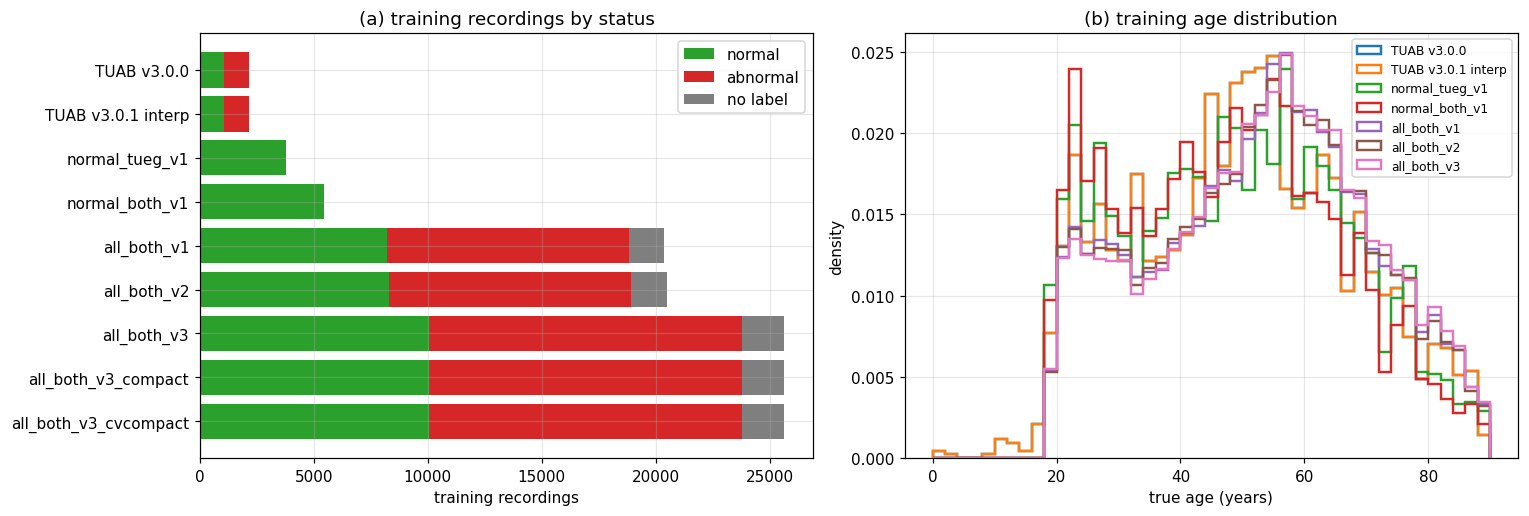

In [5]:
if HAVE_TUH:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
    tr = table_1_2.xs("train", level="split")
    order = [n for n, *_ in DATASETS]
    tr = tr.reindex(order)
    left = np.zeros(len(tr))
    for col, color in (("normal", "tab:green"), ("abnormal", "tab:red"), ("no label", "tab:gray")):
        axes[0].barh(range(len(tr)), tr[col], left=left, color=color, label=col)
        left += tr[col].to_numpy()
    axes[0].set_yticks(range(len(tr)), tr.index)
    axes[0].invert_yaxis()
    axes[0].set_xlabel("training recordings")
    axes[0].legend(loc="upper right")
    axes[0].set_title("training recordings by status")
    bins = np.arange(0, 92, 2)
    for name, _, path, _, _ in DATASETS:
        if name in ("all_both_v3_compact", "all_both_v3_cvcompact"):
            continue
        d = os.path.join(TUH, path)
        if os.path.exists(os.path.join(d, "cohort.parquet")):
            c = pd.read_parquet(os.path.join(d, "cohort.parquet"))
            ages = c.age[c.split == "train"]
        else:
            meta = json.load(open(os.path.join(d, "age_metadata.json")))["recordings"]
            files = json.load(open(os.path.join(d, "age_split.json")))["files"]["train"]
            stems = {os.path.basename(f).rsplit("_", 1)[0] for f in files}
            ages = pd.Series([meta[s]["age"] for s in stems if s in meta])
        axes[1].hist(ages, bins=bins, density=True, histtype="step", lw=1.6, label=name)
    axes[1].set_xlabel("true age (years)")
    axes[1].set_ylabel("density")
    axes[1].legend(fontsize=8)
    axes[1].set_title("training age distribution")
    panel_labels(axes)
    assert_max_columns(fig)
    fig.tight_layout()
    plt.show()

**TUEG, the source corpus.** Every cohort above draws from TUEG v2.0.2, the full TUH EEG corpus
(`$LABRAM_TUH_ROOT/tueg/v2.0.2`). Tables 1.3–1.6 and Figure 1.2 specify it from two files:
* the TUH recording index, one row per EDF over all TUH corpora (`index/tuh_index.parquet`,
  `dataset_maker/tuh_index.py`);
* NEDC's clinical sheet, one row per session, joined on patient + session
  (`index/nedc/metadata_v12.xlsm.xlsx`, `dataset_maker/tuh_clinical.py`).

`labram/eval/research_summary.py::tueg_recordings` builds the joined table. For a set $S$ of the
$N = |\mathrm{TUEG}|$ recordings, with recording $i$ lasting $d_i$ seconds:

$$ H(S) = \frac{1}{3600}\sum_{i\in S} d_i, \qquad \%(S) = 100\,\frac{\lvert S\rvert}{N} \tag{1.1} $$

A recording's **status** is the TUAB folder label where the recording is in TUAB. Otherwise it is
the report finding of the clinical sheet: abnormal when the sheet's "abnormal due to" field is filled.
Recordings whose session is not in the sheet have no label
(`dataset_maker/make_cohort_dataset.py::label_of`, the label the `all_both` cohorts use):

$$ \mathrm{status}_i = \begin{cases} \text{TUAB label} & i \in \mathrm{TUAB} \\
   \text{abnormal if the report gives a cause, else normal} & i \notin \mathrm{TUAB},\ \text{session in sheet} \\
   \text{no label} & \text{otherwise} \end{cases} \tag{1.2} $$

Ages are in years, from the EDF header. TUH writes 999 for patients aged 90 or older (a HIPAA
redaction), and those recordings count as age-unknown. Age statistics use the recordings with a
known age $a_i$: mean $\bar a$, sample standard deviation and quartiles $Q_1$, median, $Q_3$:

$$ \bar a = \frac{1}{n}\sum_{i=1}^{n} a_i, \qquad s_a = \sqrt{\frac{1}{n-1}\sum_{i=1}^{n}(a_i-\bar a)^2} \tag{1.3} $$

Data volume required.

### Table 1.3. TUEG at a glance

One row per quantity (`rs.tueg_overview`):
* `size`: recordings, patients, sessions and hours (Eq. (1.1));
* `recording`: length, year, sampling rate and montage. The year range omits a few EDF headers with
  impossible dates;
* `channels`: whether the recording has all 23 channels the models read;
* `patient`: sex and age (Eq. (1.3)), counted over recordings, so a patient with several
  recordings counts several times.

In [6]:
TUEG_INDEX = os.path.join(TUH, "index/tuh_index.parquet")
TUEG_SHEET = os.path.join(TUH, "index/nedc/metadata_v12.xlsm.xlsx")
HAVE_TUEG = os.path.exists(TUEG_INDEX) and os.path.exists(TUEG_SHEET)
if HAVE_TUEG:
    tueg = rs.tueg_recordings(TUEG_INDEX, TUEG_SHEET)
    display(numbered_table(rs.tueg_overview(tueg).set_index(["group", "quantity"]), "1.3", "TUEG at a glance"))
else:
    print("TUH recording index / clinical sheet not found: set LABRAM_TUH_ROOT to show Tables 1.3-1.6.")

### Table 1.4. Subsets of TUEG

The other TUH corpora are subsets of TUEG: the same EDF files, each corpus adding its own label. One
recording can be in several of them, so the rows overlap (`rs.tueg_subsets`). The last four rows are
the subsets the brain-age cohorts select from:
* `TUEG only`: in no other corpus;
* `in the NEDC clinical sheet`: has a report status (Eq. (1.2));
* `adult age (18–89 y)`: the age range of the cohorts;
* `normative`: the pool of the `normal_*` cohorts (`dataset_maker/tuh_clinical.py::normative_mask`).

Columns: `recordings`, `% of TUEG` and `hours` (Eq. (1.1)), and `patients`. TUEV is not listed: none
of its recordings is in TUEG v2.0.2.

In [7]:
if HAVE_TUEG:
    display(numbered_table(rs.tueg_subsets(tueg).set_index("subset"), "1.4", "Subsets of TUEG", precision=1))

,label it carries,recordings,% of TUEG,patients,hours
subset,,,,,
in TUAB,normal / abnormal (TUAB folder),2993,4.2,2329,1141.0
in TUSZ,seizure events,8140,11.5,675,1480.7
in TUEP,epilepsy / no epilepsy (patient),2808,4.0,200,635.5
in TUAR,artifact events,310,0.4,213,95.2
in TUSL,slowing events,112,0.2,38,26.8
TUEG only,–,57836,81.7,13448,24024.5
in the NEDC clinical sheet,"report finding, 15 diagnosis flags, medications",60272,85.1,14508,24956.2
adult age (18–89 y),age,68077,96.1,14025,25795.6
normative,"report-normal, no neurological diagnosis, not sedated, 18–89 y",14343,20.2,4773,4569.7


### Table 1.5. TUEG status labels and age per label

One row per status (Eq. (1.2)) and label source (`rs.tueg_status`):
* `TUAB folder`: TUAB's normal/abnormal label;
* `NEDC report`: the clinical sheet's finding;
* `all`: both sources;
* `total`: all of TUEG.

Columns:
* `recordings`, `% of TUEG` (Eq. (1.1));
* `patients`: a patient whose recordings differ in status counts under each status, so the rows sum to
  more than the total;
* `age n`: recordings with a known age;
* `age mean`, `age sd` (Eq. (1.3)), and `age Q1`, `age median`, `age Q3` in years.

Where TUAB and the report both label a session, they agree on about 95 % of its recordings.

In [8]:
if HAVE_TUEG:
    t15 = rs.tueg_status(tueg)
    t15 = t15[["status", "source", "recordings", "% of TUEG", "patients", "age n", "age mean", "age sd",
               "age Q1", "age median", "age Q3"]].set_index(["status", "source"])
    display(numbered_table(t15, "1.5", "TUEG status labels and age per label", precision=1))

### Figure 1.2. TUEG age distribution per status and in total

True age (years) of the TUEG recordings with a known age ($n$ = `age n` of Table 1.5), in 2-year bins,
per status (Eq. (1.2)) and for all of TUEG:
* (a) Recordings per bin, stacked by status. The stack's outline is the total.
* (b) The same distributions as densities (each integrates to 1), so their shapes compare despite the
  different group sizes. The vertical ticks mark each group's median.

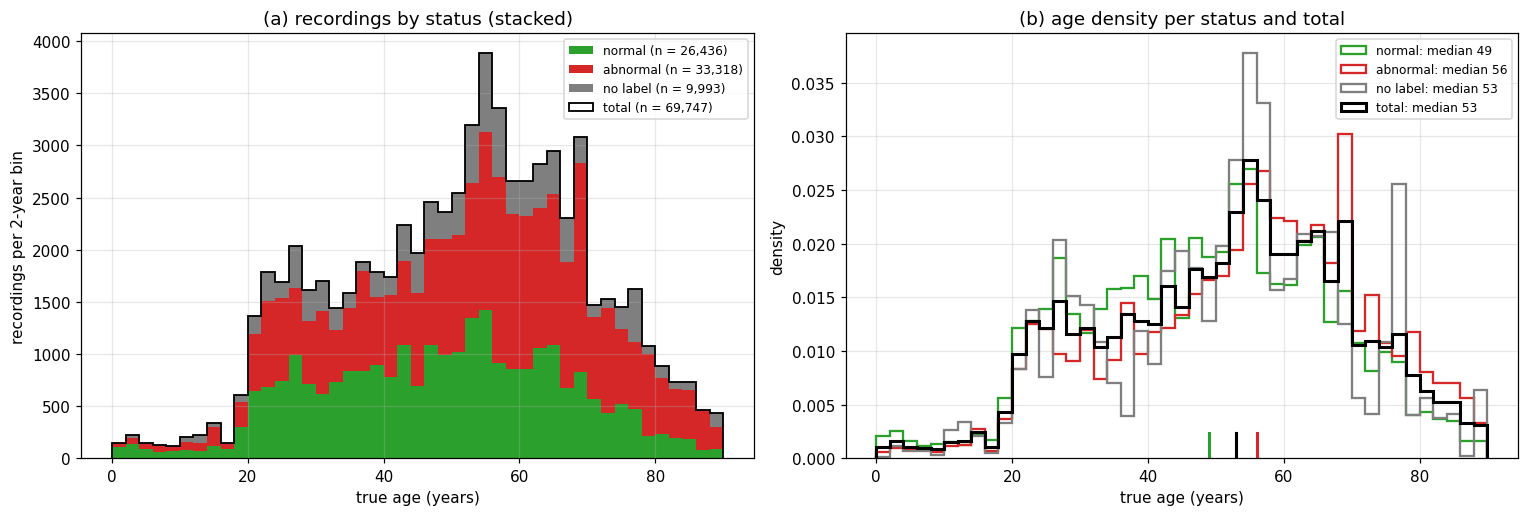

In [9]:
if HAVE_TUEG:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
    bins = np.arange(0, 92, 2)
    colors = {"normal": "tab:green", "abnormal": "tab:red", "no label": "tab:gray", "total": "k"}
    groups = {s: tueg.age[tueg.status == s].dropna() for s in rs.STATUS}
    axes[0].hist([groups[s] for s in rs.STATUS], bins=bins, stacked=True, color=[colors[s] for s in rs.STATUS],
                 label=[f"{s} (n = {len(groups[s]):,})" for s in rs.STATUS])
    axes[0].hist(tueg.age.dropna(), bins=bins, histtype="step", color="k", lw=1.2,
                 label=f"total (n = {tueg.age.notna().sum():,})")
    axes[0].set_xlabel("true age (years)")
    axes[0].set_ylabel("recordings per 2-year bin")
    axes[0].legend(fontsize=8)
    axes[0].set_title("recordings by status (stacked)")
    groups["total"] = tueg.age.dropna()
    for s, a in groups.items():
        axes[1].hist(a, bins=bins, density=True, histtype="step", lw=2.0 if s == "total" else 1.5,
                     color=colors[s], label=f"{s}: median {a.median():.0f}")
        axes[1].axvline(a.median(), ymin=0, ymax=0.06, color=colors[s], lw=2)
    axes[1].set_xlabel("true age (years)")
    axes[1].set_ylabel("density")
    axes[1].legend(fontsize=8)
    axes[1].set_title("age density per status and total")
    fig.tight_layout()
    panel_labels(axes)
    assert_max_columns(fig)
    plt.show()

### Table 1.6. TUEG diagnosis flags

The clinical sheet's 15 diagnosis flags and two derived flags over the TUEG recordings in the sheet,
most frequent first (`rs.tueg_diagnoses`):
* `any neurological diagnosis`: seizure (clinical or electrographic), epilepsy, stroke, Parkinson's,
  Alzheimer's, TBI, dementia or MS;
* `sedating medication`: an anaesthetic, benzodiazepine, barbiturate or opioid on the medication list.

Columns:
* `recordings` and `patients` with the flag;
* `% of sheet`: Eq. (1.1) relative to the sheet's recordings instead of $N$;
* `age mean`: Eq. (1.3), in years;
* `% abnormal`: the share with status abnormal (Eq. (1.2)).

The 14 pathology groups of the condition vector (Eq. (3.6)) come from these flags.

In [10]:
if HAVE_TUEG:
    display(numbered_table(rs.tueg_diagnoses(tueg).set_index("flag"), "1.6", "TUEG diagnosis flags", precision=1))

,recordings,patients,% of sheet,age mean,% abnormal
flag,,,,,
sedating medication,23067,4727,38.3,52.3,60.4
any neurological diagnosis,11560,1736,19.2,51.1,66.3
Clinical seizure,6980,1092,11.6,48.5,58.1
Epilepsy,4660,306,7.7,47.0,57.3
Electrographic seizure,3015,66,5.0,54.5,89.1
Stroke,2590,539,4.3,61.3,84.4
Substance abuse / dependence,2083,725,3.5,45.7,71.6
TBI,720,202,1.2,48.6,79.6
Bipolar disorder,502,240,0.8,42.7,51.6


**Reading Tables 1.3–1.6 and Figure 1.2.**
* **Size:** TUEG holds about 70.8k recordings (27k hours) of about 15k patients. The cohorts use 25k–29k
  of them, after the age, length, channel and per-patient rules of Table 1.1.
* **Recordings per patient:** most patients have a single recording, but a few long-monitored patients
  have hundreds. This is why the cohorts cap train/val recordings per patient and every split is by
  patient.
* **Labels:** only 4 % of TUEG is in TUAB. The status of nearly all other recordings comes from the NEDC
  report: about half are abnormal, and 14 % have no label (Table 1.5).
* **Age:** abnormal recordings are older than normal ones by about 5 years in mean and 7 in median
  (Table 1.5, Figure 1.2(b)). A model trained on mixed statuses can therefore partly read age from
  pathology, which is one reason Section 5 reports normal and abnormal test recordings separately.

## 2. Experiments

**Phase 1 (TUAB only)** starts from scenario **D**, the default `finetune_tuab_age.json` (Table 2.1
lists how it differs from LaBraM's own fine-tuning recipe):
* LaBraM-base with a **common average reference (CAR)** on the input (Eq. (3.1));
* Huber loss on the z-scored age;
* lr $10^{-4}$, 15 epochs.

**CAR** re-references the EEG. At every time sample it subtracts the mean over all channels from each
channel, so every channel is measured against the average of all electrodes instead of the recording's
own reference. This removes what all electrodes share: the activity of the reference electrode(s) and
noise common to every channel. It also puts the two TUH montages on one reference, average reference
(`tcp_ar`, about 80 % of the recordings) and linked ears (`tcp_le`). LaBraM as published feeds the
signal on each recording's own reference. CAR is the only part of the LaBraM++ input block D uses: there is no per-patch
z-scoring (Table 2.1). In Table 5.2, row P1 tests it.

**E2** shortens it to 4 epochs / 1 warmup epoch, and **M1** = E2 + mixup $\alpha = 0.4$. Every
**phase-2** run is M1 plus the change named in its row (`labram/eval/research_summary.py::M1`).
**Phase 3** cross-validates the three strongest phase-2 configurations.

**Loss.** Every run trains on a loss from the family of Eqs. (2.1)–(2.11) below, and Tables 2.2–2.4 name
each run's loss in their `loss` column.

**ClearML.** Tables 2.2–2.5 link every run to its ClearML experiment; the link text is the
experiment's name in ClearML (`docs/data/brain_age_clearml_runs.csv`, written from the ClearML server
by `labram/eval/research_summary.py::fetch_clearml_runs`). A CV run links to the ClearML project that
holds its five fold experiments.

### Table 2.1. Base configuration D versus the LaBraM fine-tuning recipe

Every configuration field on which LaBraM's TUAB fine-tuning recipe as published and the base
configuration D differ:
* `LaBraM paper`: `labram/configs/defaults/finetune_tuab_paper.json`, the normal/abnormal fine-tune of
  LaBraM-base from the paper and the README;
* `D`: `labram/configs/defaults/finetune_tuab_age.json` as is, without overrides.

Both are rebuilt by `rs.resolve_config` and compared by `labram/eval/research_summary.py::config_diff`.
Excluded:
* bookkeeping fields (paths, logging, infrastructure);
* classification-only fields a regression run never reads (`INERT_FOR_REGRESSION`, e.g. label smoothing);
* fields of a section that is off in both.

`group` is the part of the pipeline and `meaning` what the change does. Every other field is the
paper's: LaBraM-base from `labram-base.pth`, batch 64, AdamW with weight decay 0.05, layer decay 0.65,
drop path 0.1, mean pooling, cosine schedule. Changes that live in the data rather than the
configuration (mains-interference removal, splits, labels) are in Table 4.2; how the best configuration
differs from the paper's recipe is Table 4.1.

In [11]:
BASE_MEANING = {
    "data.dataset": ("task", "age regression on TUAB (age from the EDF header) instead of normal/abnormal"),
    "model.task": ("task", "scalar regression head, Huber loss on the z-scored age (Eqs. (3.2), (3.4))"),
    "data.data_format": ("data", "storage only: one float32 npy per recording, windows bit-identical to the pickles"),
    "labram_plus.enabled": ("input", "LaBraM++ input block on: common average reference, CAR (Eq. (3.1))"),
    "labram_plus.z_score_patches": ("input", "LaBraM++ block with CAR only, no per-patch z-scoring"),
    "data.trim_start_sec": ("windows", "drop the first 60 s of every recording"),
    "data.trim_end_sec": ("windows", "drop the last 60 s of every recording"),
    "data.eval_minutes": ("windows", "score each recording on its first 5 minutes after the trim"),
    "evaluation.agg_windows": ("scoring", "one prediction per recording = mean of its windows (Eq. (3.7))"),
    "optimizer.lr": ("optimizer", "peak lr 1e-4 instead of 5e-4"),
    "optimizer.warmup_epochs": ("schedule", "2 warmup epochs instead of 5"),
    "trainer.epochs": ("schedule", "15 epochs instead of 50"),
}
base_d = rs.resolve_config(AGE_JSON)
paper = rs.resolve_config(PAPER_JSON)
t2_1 = rs.config_diff(paper, base_d, ("LaBraM paper", "D"), ignore=rs.NON_SCIENTIFIC + rs.INERT_FOR_REGRESSION)
missing = sorted(set(t2_1.field) - set(BASE_MEANING))
assert not missing, f"annotate these fields in BASE_MEANING: {missing}"
t2_1["group"] = t2_1.field.map(lambda f: BASE_MEANING[f][0])
t2_1["meaning"] = t2_1.field.map(lambda f: BASE_MEANING[f][1])
order = ["task", "data", "input", "windows", "scoring", "optimizer", "schedule"]
t2_1 = t2_1.sort_values("group", key=lambda g: g.map(order.index), kind="stable").set_index(["group", "field"])
numbered_table(t2_1, "2.1", "Base configuration D versus the LaBraM fine-tuning recipe")

**Loss functions.** The loss is what the optimizer minimizes on every training batch. LaBraM as
published fine-tunes TUAB as a binary normal/abnormal classifier. The head emits one logit $s$ per
window with label $c \in \{0, 1\}$, and the loss is the binary cross-entropy (`nn.BCEWithLogitsLoss`,
`labram/losses/classification.py`):

$$ \ell_{\mathrm{BCE}}(s, c) = -\big[c \log \sigma(s) + (1-c)\log(1-\sigma(s))\big], \qquad \sigma(s) = \frac{1}{1+e^{-s}} \tag{2.1} $$

For brain age the head instead emits a scalar $\hat z$ per 10 s window. The target is the z-scored age
$z = (y-\mu)/\sigma$ (Eq. (3.2), with $\mu$ and $\sigma$ from the training windows). The batch loss
averages a per-window loss $\ell$ of the residual over the $B$ windows of the batch
(`labram/losses/regression.py::build_regression_criterion`):

$$ \mathcal L = \frac{1}{B}\sum_{b=1}^{B} \ell(r_b), \qquad r_b = \hat z_b - z_b \tag{2.2} $$

**Per-window loss.** The default for D and every later run unless stated otherwise is the **Huber**
loss with $\delta = 1$. It is quadratic for small residuals and linear for large ones, so a few
recordings with a wrong or extreme age do not dominate the gradient. DX2 uses $\delta = 2$:

$$ \ell_\delta(r) = \begin{cases} \tfrac12 r^2 & \lvert r\rvert \le \delta \\ \delta\,(\lvert r\rvert - \tfrac12\delta) & \text{otherwise} \end{cases} \tag{2.3} $$

D2 uses the **L1** loss, the absolute error, which directly matches the MAE of Eq. (0.1):

$$ \ell_1(r) = \lvert r\rvert \tag{2.4} $$

**Mixup (M1 and every phase-2 run).** Each window $b$ of a batch is blended with a partner window
$\pi(b)$ drawn from the same batch, usually from another recording with a different age. $\pi$
permutes the **samples of the batch** (`torch.randperm` over the batch dimension), not the channels.
The two windows are averaged point by point, channel with the same channel and time sample with the
same time sample, and their targets with the same weight. For example, $\lambda = 0.7$ blends a
30-year-old's window with a 70-year-old's into target $0.7 \cdot 30 + 0.3 \cdot 70 = 42$. One
$\lambda \sim \mathrm{Beta}(0.4, 0.4)$ is drawn per batch, usually near 0 or 1, so one window dominates. The loss
of Eq. (2.2) is computed on the blended targets (`labram/train/mixup.py::mixup_batch`). A channel
missing from either partner (T1/T2 in the `channel_drop` runs) is zeroed rather than blended:

$$ \bar x_b = \lambda x_b + (1-\lambda)\,x_{\pi(b)}, \qquad \bar z_b = \lambda z_b + (1-\lambda)\,z_{\pi(b)} \tag{2.5} $$

Plain mixup draws the partner $\pi(b)$ uniformly at random. **C-Mixup** (M1c) prefers partners of similar
age, so the blended target stays plausible. With $\sigma_m = 5$ years:

$$ P\big(\pi(b) = j\big) \propto \exp\!\Big(-\frac{(y_b - y_j)^2}{2\sigma_m^2}\Big), \quad j \ne b \tag{2.6} $$

**Soft labels (M4).** The head emits a softmax $p_k$ over age bins with centres $c_k$ = 1, 2, …, 89 years.
The target is a Gaussian $q_k$ around the true age with $\sigma_s = 2.5$ years, the loss is the KL
divergence, and the prediction is the expected age (`SoftLabelRegressionLoss`). Centres and $\sigma_s$ are
z-scored like $z$:

$$ \begin{aligned} q_k &= \frac{\exp\!\big(-(c_k - z)^2 / 2\sigma_s^2\big)}{\sum_{k'}\exp\!\big(-(c_{k'} - z)^2 / 2\sigma_s^2\big)}, \qquad \ell_{\mathrm{KL}} = \sum_k q_k \log\frac{q_k}{p_k}, \\ \hat z &= \sum_k p_k\, c_k \end{aligned} \tag{2.7} $$

**Age-balanced loss (B1, B2).** Rare ages (children, the very old) are up-weighted.
$\rho_k$ is the density of training windows in 1-year age bin $k$, smoothed by a Gaussian with
$\sigma = 2$ years. The weight is $\rho^{-1/2}$ (B1) or $\rho^{-1}$ (B2), capped at 10× the smallest weight and
normalized to mean 1 over the training windows (`age_balance_weights`, `BalancedRegressionLoss`):

$$ \mathcal L = \frac{1}{B}\sum_{b} w_{k(y_b)}\,\ell_\delta(r_b), \qquad w_k \propto \rho_k^{-1/2}\ \text{or}\ \rho_k^{-1} \tag{2.8} $$

**Codebook regularization: the spectral reconstruction and quantization terms (DX1, DX4, DX4b
only).** LaBraM's tokenizer (VQNSP) was pre-trained to encode each 1 s patch into a codeword and to
decode from it the patch's Fourier amplitude and phase. These runs reuse its quantizer and decoder,
frozen, on top of the fine-tuned encoder. Extra loss terms then penalize the encoder if its patch tokens
drift away from what the frozen decoder can read back (`model.codebook_reg`,
`labram/losses/codebook_regularized.py`). The age head still reads the mean patch token, as in D.

For each patch token $n$ (one channel × one 1 s patch of 200 samples):
* $\tilde A_{n,k}$: the std-normalized FFT amplitude of the patch at frequency bin $k$ (bin $k$ = $k$ Hz);
* $\hat A_{n,k}$: the decoder's reconstruction of it;
* $h_n$: the encoder token;
* $e_n$: its nearest codeword; $\mathrm{sg}$ is stop-gradient.

The terms are averaged over all tokens (and bins or feature dimensions) of the batch:

$$ \begin{aligned} \mathcal L &= \mathcal L_\delta + w_A\,\mathcal L_{\mathrm{amp}} + w_P\,\mathcal L_{\mathrm{phase}} + w_Q\,\mathcal L_{\mathrm{q}}, \\ \mathcal L_{\mathrm{amp}} &= \operatorname{mean}_{n,\,k \le K}\big(\hat A_{n,k} - \tilde A_{n,k}\big)^2, \\ \mathcal L_{\mathrm q} &= \beta_q\,\operatorname{mean}_{n}\,\big(\mathrm{sg}(e_n) - h_n\big)^2, \qquad \beta_q = 1 \end{aligned} \tag{2.9} $$

$\mathcal L_{\mathrm{phase}}$ is the same MSE on the std-normalized FFT phase. $K$ is the number of
frequency bins kept: `loss.freq_fraction` × 200. The weights each run used, from its ClearML
configuration (`model.codebook_reg.*_weight`):

* **DX1:** $w_A = 1$, $w_P = 0$, $w_Q = 0$, so amplitude reconstruction only. `freq_fraction` = 0.5 keeps
  $K = 100$ bins, 0–99 Hz. That is the whole non-redundant half of the spectrum: for a real signal, the
  upper 100 bins mirror the lower ones.
* **DX4:** $w_A = 0$, $w_P = 0$, $w_Q = 1$, so the quantization (commitment) term only. No reconstruction.
* **DX4b:** as DX4 with $w_Q = 50$.
* **Phase** ($w_P$) is 0 in all three. The phase reconstruction loss was never applied in any
  fine-tune of this study.
* **Every other run** has `model.codebook_reg.enabled=false`. The model then has no quantizer or decoder,
  and all three terms are absent. The `loss.amplitude_weight` / `phase_weight` / `embedding_weight`
  fields that read 1.0 in every run's ClearML configuration belong to the VQNSP tokenizer's own
  training and are never read by a fine-tune.

None of the three helped. Compared with D, the test MAE changes by +0.24 (DX1), +0.14 (DX4) and +0.36
(DX4b), all worse but all within seed noise, τ = 0.38 (Eq. (5.2)). Table 5.2 tests DX1 and DX4 in rows P17
and P18.

**Multi-task (MT1).** A second output predicts the normal/abnormal label $c$ with the BCE of Eq. (2.1),
weighted 0.5 (`MultiTaskAgeCriterion`). Selection still uses the age MAE:

$$ \mathcal L = \mathcal L_\delta + 0.5\,\frac{1}{B}\sum_b \ell_{\mathrm{BCE}}(s_b, c_b) \tag{2.10} $$

**Channel-dropout consistency (Exp4aug, Exp4aug15, cvaug).** With probability 0.2 per batch, 1–2 of the
T1/T2 channels are dropped from every sample. The age loss is computed on that dropped pass. The
feature $f$ the head reads should not change: it is pulled towards the feature $f^{\mathrm{full}}$ of a
frozen all-channels pass, with $\lambda = 0.1$, over the samples $A$ that lost a channel and the feature
dimensions $d = 1..D$ (`labram/train/channel_drop.py`):

$$ \mathcal L = \mathcal L_\delta^{\mathrm{drop}} + \lambda\,\frac{1}{\lvert A\rvert D}\sum_{b\in A}\sum_{d=1}^{D}\big(f^{\mathrm{full}}_{b,d} - f^{\mathrm{drop}}_{b,d}\big)^2 \tag{2.11} $$

Here $\mathcal L_\delta$ is Eq. (2.2) with the Huber loss of Eq. (2.3). Changes that do not touch the loss
(EMA evaluation, layer decay, dropout, heads, input conditioning) keep Huber $\delta = 1$, with mixup
wherever the run's `loss` column says so.

### Table 2.2. Phase 1: TUAB-only runs

The experiment registry's master table (`docs/age_overfitting_experiments.md`, Table 12.1).

Columns:
* `ClearML`: the run's ClearML experiment, linked by its name.
* `family` and `change`: the question the run belongs to, and what it changes relative to D unless it
  names another run. Abbreviations:
  * CAR common average reference; ep epochs; lr learning rate;
  * ld layer decay; dp drop path; drop dropout; wd weight decay; clip gradient clipping at norm 1;
  * EMA evaluation with an exponential moving average of the weights;
  * LoRA r16 low-rank adapters of rank 16 instead of full fine-tuning;
  * CLS the class token; MLP a two-layer head.
* `loss`: the run's training loss, read from its ClearML configuration (Eqs. (2.2)–(2.11)).
* `val` / `test`: MAE (Eq. (0.1), years) at the epoch with the lowest validation MAE. Phase 1 is
  **TUAB only**, in training and evaluation:
  * `val`: TUAB's validation split, 556 recordings (291 normal, 265 abnormal);
  * `test`: TUAB's official evaluation set, 274 recordings.
* `N` / `A`: the same TUAB test MAE restricted to its 149 normal and 125 abnormal recordings.
* `β`: the bias slope of Eq. (0.5) on the 274 TUAB test recordings. Every model regresses towards
  the mean age. The fine-tuned runs sit between −0.46 and −0.33, and the from-scratch runs S1–S3 at
  −0.49 to −0.52. The collapsed runs (C2, C2-head, C2-last, DX3, F2; test MAE above 13) reach −0.8
  to −1.0, meaning they predict almost a constant age.
* `e*/E`: the selected epoch $e^\star$ and the number of epochs $E$.

**Same data split in every run.** Every run records the recordings of its train, val and test splits
(the `data_split` artifact of its ClearML experiment), saved here as SHA-1 digests of the sorted
recording lists (`docs/data/brain_age_run_splits.csv`, `rs.split_fingerprint`, regenerated by
`rs.fetch_run_splits`). The check below the table compares them: all phase-1 runs train, validate and
test on identical recordings, with no patient in two splits. Only the number of windows differs, where
the run changes the windows: A scores whole recordings, and C uses 30 s windows. Phase 2's `Control`
uses the same split.

**Why some `N` / `A` are missing ("–").** The per-cohort test metrics were added to the trainer on
2026-10-07 06:47 UTC (commit `62b159d`). 16 of the 21 runs without them started before that. The
other five (E2, DX3, E1, E1c, E2c) are SageMaker jobs started 07:06–08:30 the same day whose job code
did not include the change yet. All 21 logged only the overall val/test MAE. They saved no per-recording predictions, so the split
by status cannot be recomputed from their logs; it needs a new inference pass of their checkpoints.
Their `test` column is on the same 274 recordings as everyone else's.

The pre-study baseline (LaBraM fine-tuned with the original recipe adapted to regression) scored val
8.31 / test 9.04 (`docs/age_training_scenario_D.md`, Section 1).

In [12]:
t21 = reg.assign(ClearML=reg.run.map(cml.link), loss=reg.run.map(rs.run_loss),
                 epochs_=[f"{b:.0f}/{e:.0f}" for b, e in zip(reg.best_epoch, reg.epochs)])
t21 = t21[["run", "ClearML", "family", "change", "loss", "val", "test", "test_normal", "test_abnormal", "beta",
           "epochs_"]].rename(columns={"test_normal": "N", "test_abnormal": "A", "beta": "β", "epochs_": "e*/E"})
display(numbered_table(t21.set_index("run"), "2.2", "Phase 1 runs"))

# split check: identical train/val/test recording lists (digests) across the phase-1 runs
p1 = list(reg.run)
groups = split_sig.loc[p1].groupby(split_sig.loc[p1]).groups
assert len(groups) == 1, f"phase-1 runs differ in their split: {dict(groups)}"
n = run_splits[run_splits.run == "D"].set_index("split")
win = run_splits[run_splits.run.isin(p1)].pivot(index="run", columns="split", values="windows")
odd = win[(win != win.loc["D"]).any(axis=1)].index.tolist()
same = sorted(r for r in split_sig.index if r not in p1 and split_sig[r] == split_sig["D"])
print(f"Split check: all {len(p1)} phase-1 runs use the same recordings: train {n.recordings['train']:,} "
      f"({n.patients['train']:,} patients), val {n.recordings['val']} ({n.patients['val']}), "
      f"test {n.recordings['test']} ({n.patients['test']}). Window counts differ only for {', '.join(odd)}. "
      f"Same split outside phase 1: {', '.join(same)}.")

,ClearML,family,change,loss,val,test,N,A,β,e*/E
run,,,,,,,,,,
A,age_A_ep15_lr1e-4_fullrec_20261005_043322_643,Evaluation protocol,B with whole-recording val/test,Huber δ 1 (2.3),8.29,9.03,–,–,-0.46,2/12
B,age_B_eval5min_20261005_064356_435,Evaluation protocol,"CAR off, 15 ep, lr 1e-4, 5-min eval (pre-D baseline)",Huber δ 1 (2.3),8.40,8.91,–,–,-0.43,2/6
D,age_D_eval5min_car_20261005_013250_973,Baseline,B + CAR (finetune_tuab_age.json),Huber δ 1 (2.3),7.77,8.30,–,–,-0.40,1/15
D-npy,age_D_eval5min_car_npy_file_20261006_185443_758,Baseline (repro),D on the npy format,Huber δ 1 (2.3),7.77,8.30,–,–,-0.40,1/15
D-cohorts,age_D_npy_cohorts_20261007_064710_242,Baseline (repro),"D, local, cohort metrics",Huber δ 1 (2.3),7.77,8.31,6.57,10.38,-0.40,1/15
E2,age_E2_npy_ep4_warm1_20261007_070635_244,Schedule,"D, 4 ep / 1 warmup",Huber δ 1 (2.3),7.68,8.25,–,–,-0.37,3/4
L1,age_L1_ep12_mixup_ema_20261009_095540_331,Schedule,M12 on 12 ep / 2 warmup,"Huber δ 1 + mixup (2.3, 2.5)",7.51,8.47,6.65,10.63,-0.42,3/12
C2,age_C2_eval5min_regularized_20261005_012652_087,Classic regularizers,"B + ld 0.5, dp 0.2, drop 0.1, wd 0.1, clip 1",Huber δ 1 (2.3),12.47,13.52,–,–,-0.81,14/15
DX3,age_DX3_npy_regularized_20261007_070603_726,Classic regularizers,D + C2 bundle,Huber δ 1 (2.3),12.83,14.90,–,–,-1.00,0/15


Split check: all 45 phase-1 runs use the same recordings: train 2,145 (1,650 patients), val 556 (412), test 274 (251). Window counts differ only for A, C. Same split outside phase 1: Control.


### Table 2.3. Phase 2: TUH cohort runs

One row per run of `docs/data/tuh_cohort_eval_v1.csv`, from `labram/eval/research_summary.py::PHASE2`:
* `ClearML`: the run's ClearML experiment, linked by its name;
* `cohort` (Table 1.1), `epochs` / `warmup`;
* `cond.`: ✓ if the head also receives the recording's status and pathology vector (Eq. (3.6));
* `parent` and `change`: the run it is compared with in Section 5 and what differs;
* `loss`: the training loss (Eqs. (2.2)–(2.11)). Every phase-2 run is M1, Huber + mixup; the T1/T2
  dropout runs add the consistency term.

Metrics:
* `test all` / `normal` / `abnormal`: MAE (Eq. (0.1)) on the **TUAB test set only**, all 274 recordings
  and its 149 normal / 125 abnormal ones. The phase-2 runs train on TUEG too, but none of them is
  tested on TUEG recordings: TUAB test is the one set every run shares (Section 0).
* `R² normal`: Eq. (0.2) on the normal TUAB test recordings;
* `TUEG val v2`: MAE on the TUEG part of the shared v2 validation split (2,325 recordings no v2/v3
  model trained on), available only for runs scored on it. It is the only TUEG number in the table.
  Each run's own validation split is not shown, because it differs from cohort to cohort.
* No `β`: the cohort evaluation (`docs/data/tuh_cohort_eval_v1.csv`) stores MAE, RMSE and R² but not
  the bias slope, so $\beta$ is reported for phase 1 only.

**Same split or not.** The check below the table groups the runs by their recorded train/val/test
recordings, as for Table 2.2:
* Runs on the same cohort share one split. Exp1f's `normal_both_v1_meta` holds the same recordings as
  `normal_both_v1`, and `all_both_v3_compact` the same as `all_both_v3`.
* **Exp3q is the exception** within `all_both_v1`. Its signal-quality filter drops windows beyond
  ±800 µV and windows with a flat channel, and recordings left without windows drop out. That leaves
  19,815 instead of 20,368 train recordings and 2,836 instead of 2,905 val recordings, and its test
  loses 10 windows but keeps all 274 recordings.
* Splits differ across cohorts by design (Table 1.1): `v1`, `v2` and `v3` assign TUEG patients
  differently, so their val MAEs do not compare.
* Every run with a test split tests on the same 274 TUAB recordings. Exp2 (`normal_tueg_v1`) has no
  test split.

In [13]:
def cohort_metric(model, split, source, cohort, col="MAE"):
    s = coh[(coh.model == model) & (coh.split == split) & (coh.source == source) & (coh.cohort == cohort)]
    return float(s[col].iloc[0]) if len(s) else np.nan


rows = []
for e in rs.PHASE2:
    if e.name not in set(coh.model):
        continue
    rows.append({"run": e.name, "ClearML": cml.link.get(e.name, "–"), "cohort": e.cohort, "epochs": f"{e.epochs} / {e.warmup}",
                 "cond.": "✓" if e.conditions else "", "parent": e.parent, "change": e.change, "loss": rs.run_loss(e.name),
                 "test all": cohort_metric(e.name, "test", "TUAB", "all"),
                 "normal": cohort_metric(e.name, "test", "TUAB", "normal"),
                 "abnormal": cohort_metric(e.name, "test", "TUAB", "abnormal"),
                 "R² normal": cohort_metric(e.name, "test", "TUAB", "normal", "R2"),
                 "TUEG val v2": cohort_metric(e.name, "val_v2", "TUEG", "all")})
t22 = pd.DataFrame(rows).set_index("run")
display(numbered_table(t22, "2.3", "Phase 2 runs"))

# split check: runs grouped by identical train/val/test recording lists
p2 = [n for n in t22.index if n in split_sig.index]
for sig, runs in split_sig.loc[p2].groupby(split_sig.loc[p2]).groups.items():
    print(f"same split: {', '.join(runs)}  (cohort {', '.join(sorted({rs.EXPERIMENTS[r].cohort for r in runs}))})")
tests = {s.split("/")[2] for s in split_sig.loc[p2] if s.split("/")[2] != "-"}
print(f"TUAB test recordings identical in every phase-2 run with a test split: {tests == {split_sig['D'].split('/')[2]}}")

,ClearML,cohort,epochs,cond.,parent,change,loss,test all,normal,abnormal,R² normal,TUEG val v2
run,,,,,,,,,,,,
Control,tuh_control_tuab_only_M1_interp_20261012_152904_458,tuab_v3.0.1_interp50-60,4 / 1,,,M1 on TUAB only (the TUAB baseline of phase 2),"Huber δ 1 + mixup (2.3, 2.5)",8.23,6.42,10.39,0.75,9.29
Exp1,tuh_exp1_normal_both_M1_20261012_133302_883,normal_both_v1,4 / 1,,Control,train on normal recordings only: TUAB normal + TUEG normal,"Huber δ 1 + mixup (2.3, 2.5)",8.03,5.99,10.47,0.78,8.68
Exp2,tuh_exp2_normal_tueg_M1_20261012_134712_671,normal_tueg_v1,4 / 1,,Exp1,TUEG normal only (no TUAB in training),"Huber δ 1 + mixup (2.3, 2.5)",8.00,6.06,10.31,0.78,8.75
Exp1b,tuh_exp1b_normal_both_M1_ep10_20261012_175842_602,normal_both_v1,10 / 3,,Exp1,10 epochs / 3 warmup instead of 4 / 1,"Huber δ 1 + mixup (2.3, 2.5)",8.11,6.09,10.52,0.77,8.66
Exp1t,tuh_exp1t_normal_both_M1_ep4_feat-tokens_20261013_091030_953,normal_both_v1,4 / 1,,Exp1,classical EEG features as extra transformer tokens,"Huber δ 1 + mixup (2.3, 2.5)",8.80,7.17,10.73,0.70,–
Exp1f,tuh_exp1f_normal_both_M1_ep4_feat-only_20261012_235557_718,normal_both_v1_meta,4 / 1,,Exp1,"classical EEG features only, MLP head, no EEG encoder","Huber δ 1 + mixup (2.3, 2.5)",8.13,6.21,10.41,0.77,–
Exp3,tuh_exp3_all_both_M1_20261012_140234_136,all_both_v1,4 / 1,,Control,"add every TUEG recording (normal, abnormal, unlabelled): ~10x training data","Huber δ 1 + mixup (2.3, 2.5)",7.26,5.57,9.28,0.80,–
Exp3b,tuh_exp3b_all_both_M1_ep10_20261012_205133_238,all_both_v1,10 / 3,,Exp3,10 epochs / 3 warmup instead of 4 / 1,"Huber δ 1 + mixup (2.3, 2.5)",7.70,6.17,9.51,0.75,–
Exp3q,tuh_exp3q_all_both_M1_ep4_qc800-0.5_20261013_110534_570,all_both_v1,4 / 1,,Exp3,drop windows beyond ±800 µV or with a flat channel,"Huber δ 1 + mixup (2.3, 2.5)",7.34,5.69,9.31,0.79,–


same split: Exp1, Exp1b, Exp1t, Exp1f  (cohort normal_both_v1, normal_both_v1_meta)
same split: Exp3v2, Exp3cond, Exp3clscond  (cohort all_both_v2)
same split: Control  (cohort tuab_v3.0.1_interp50-60)
same split: Exp4drop, Exp4base, Exp4basec, Exp4ctrl, Exp4aug, Exp4aug15  (cohort all_both_v3, all_both_v3_compact)
same split: Exp3q  (cohort all_both_v1)
same split: Exp3, Exp3b, Exp3c  (cohort all_both_v1)
same split: Exp2  (cohort normal_tueg_v1)
TUAB test recordings identical in every phase-2 run with a test split: True


### Table 2.4. Phase 3: five-fold cross-validation

* **Folds:** the pool is `all_both_v3_cvcompact` train + val (29,035 recordings), split into 5
  patient-disjoint folds. For fold $k$, test = fold $k$, val = fold $k+1 \bmod 5$, and the other three
  train. The TUAB test set is in no fold, so each of the 5 fold models also scores it.
* **`ClearML`:** the ClearML project holding the run's five fold experiments, linked by its name.
* **`loss`:** the training loss (Eqs. (2.2)–(2.11)).
* **Per-fold columns:** mean ± sample sd over the 5 fold models of the MAE (Eq. (0.1)) on:
  * `CV val`: the fold's own val;
  * `CV test`: the fold's own test;
  * `TUAB test`, with `normal` and `abnormal`.
* **`ens.`:** the TUAB test MAE of the median of the 5 models' predictions (Eq. (3.8)). It needs the
  per-recording predictions.

Source: `docs/data/cv5_eval_v2.csv`.

In [14]:
def fold_stats(exp, split, source, cohort="all"):
    # mean, sample sd and count over fold models of the per-fold MAE (Eq. (0.1))
    s = cv[(cv.exp == exp) & (cv.split == split) & (cv.source == source) & (cv.cohort == cohort)]
    s = s.drop_duplicates("fold")
    return s.MAE.mean(), s.MAE.std(ddof=1), len(s)


preds = cc.long_frame(cc.load_predictions(CV_PREDS)) if HAVE_PREDS else None
STATUS = {}
if HAVE_TUH:
    _lab = json.load(open(os.path.join(TUH, "tuab/v3.0.1/edf/processed_npy/age_metadata.json")))["recordings"]
    STATUS = {s: r["label"] for s, r in _lab.items()}       # TUAB recording -> normal / abnormal


def ensemble(exp, split="heldout"):
    # median over the 5 fold models per recording (Eq. (3.8)), with the TUAB status
    e = cc.ensemble(preds[preds.exp == exp], split, "median")
    e["status"] = e.stem.map(STATUS)
    return e


def ens_mae(exp, cohort="all"):
    e = ensemble(exp)
    if cohort != "all":
        e = e[e.status == cohort]
    return float(e.err.abs().mean())


rows = []
for exp in ("cvbase", "cvctrl", "cvaug"):
    r = {"run": exp, "ClearML": cml.link[exp], "cond.": "✓" if rs.EXPERIMENTS[exp].conditions else "",
         "loss": rs.run_loss(exp)}
    for label, split, source, cohort in (("CV val", "val", "all", "all"), ("CV test", "test", "all", "all"),
                                         ("TUAB test", "heldout", "TUAB", "all"),
                                         ("normal", "heldout", "TUAB", "normal"),
                                         ("abnormal", "heldout", "TUAB", "abnormal")):
        m, sd, k = fold_stats(exp, split, source, cohort)
        r[label] = f"{m:.2f} ± {sd:.2f}"
    if preds is not None and STATUS:
        r["ens. TUAB test"] = ens_mae(exp)
        r["ens. normal"] = ens_mae(exp, "normal")
        r["ens. abnormal"] = ens_mae(exp, "abnormal")
    rows.append(r)
t23 = pd.DataFrame(rows).set_index("run")
numbered_table(t23, "2.4", "Five-fold cross-validation")

,ClearML,cond.,loss,CV val,CV test,TUAB test,normal,abnormal,ens. TUAB test,ens. normal,ens. abnormal
run,,,,,,,,,,,
cvbase,tuh_cvbase_all_both_v3_cvcompact_M1_ep5_cv5-base_cv5,,"Huber δ 1 + mixup (2.3, 2.5)",8.16 ± 0.11,8.18 ± 0.15,7.49 ± 0.09,5.81 ± 0.10,9.50 ± 0.11,7.44,5.75,9.46
cvctrl,tuh_cvctrl_all_both_v3_cvcompact_M1_ep10_cv5-ctrl_cv5,✓,"Huber δ 1 + mixup (2.3, 2.5)",8.09 ± 0.12,8.08 ± 0.13,7.28 ± 0.14,5.53 ± 0.08,9.37 ± 0.25,7.10,5.31,9.23
cvaug,tuh_cvaug_all_both_v3_cvcompact_M1_ep10_cv5-augT1T2_cv5,✓,"Huber δ 1 + mixup + 0.1 consistency (2.3, 2.5, 2.11)",8.06 ± 0.13,8.06 ± 0.15,7.33 ± 0.17,5.55 ± 0.17,9.44 ± 0.18,7.23,5.43,9.37


### Figure 2.1. TUAB test MAE of every run

Every run's TUAB test MAE (Eq. (0.1), years), in the order the runs were made, left to right. Dotted
vertical lines separate phase 1 (Table 2.2), phase 2 (Table 2.3) and the CV runs (Table 2.4).
* (a) All 274 test recordings.
* (b) The 149 normal test recordings.
* (c) The 125 abnormal test recordings.

The 21 phase-1 runs without cohort metrics (Table 2.2) have no point in (b) or (c).

**Legend.**
* **Colour = phase:** blue phase 1 (TUAB only), orange phase 2 (TUH cohorts), green phase 3
  (cross-validation).
* **Fill = what the head sees:**
  * filled marker: an EEG-only model;
  * hollow marker: the head also receives the recording's status and pathology vector (Eq. (3.6)), so
    the model is not EEG-only and its MAE is not comparable with published results.
* **Shape:**
  * circle: one model;
  * green circle with bars: the mean ± sample sd over the 5 CV fold models;
  * green star: the median ensemble of those 5 models (Eq. (3.8));
  * triangle: a collapsed run whose MAE is above the panel's top edge (11 years in (a) and (b), 14 in
    (c)). It is drawn at the edge so the axis stays readable; its true value is in Table 2.2.
* **Published results, black horizontal lines.** Both are the best published TUAB brain-age models.
  Their training data and splits differ from ours, so the lines are reference points, not a matched
  comparison.
  * Dashed: Gemein et al. 2024, a TCN ensemble trained on TUEG normal recordings only. On TUAB's
    evaluation set it scores 6.60 on normal recordings (b) and 12.85 on abnormal ones (c), **after**
    their age-bias correction; their raw normal MAE was 6.48. Our points are raw, and Table 3.5
    gives our numbers after the same kind of correction. Their
    abnormal error comes from a model that never saw an abnormal recording; ours do.
  * Dotted: Engemann et al. 2022, the best earlier result, 7.75 on TUAB normal recordings (b)
    (10-fold cross-validation).
  * Panel (a) has no line: neither paper reports one MAE over all TUAB recordings.

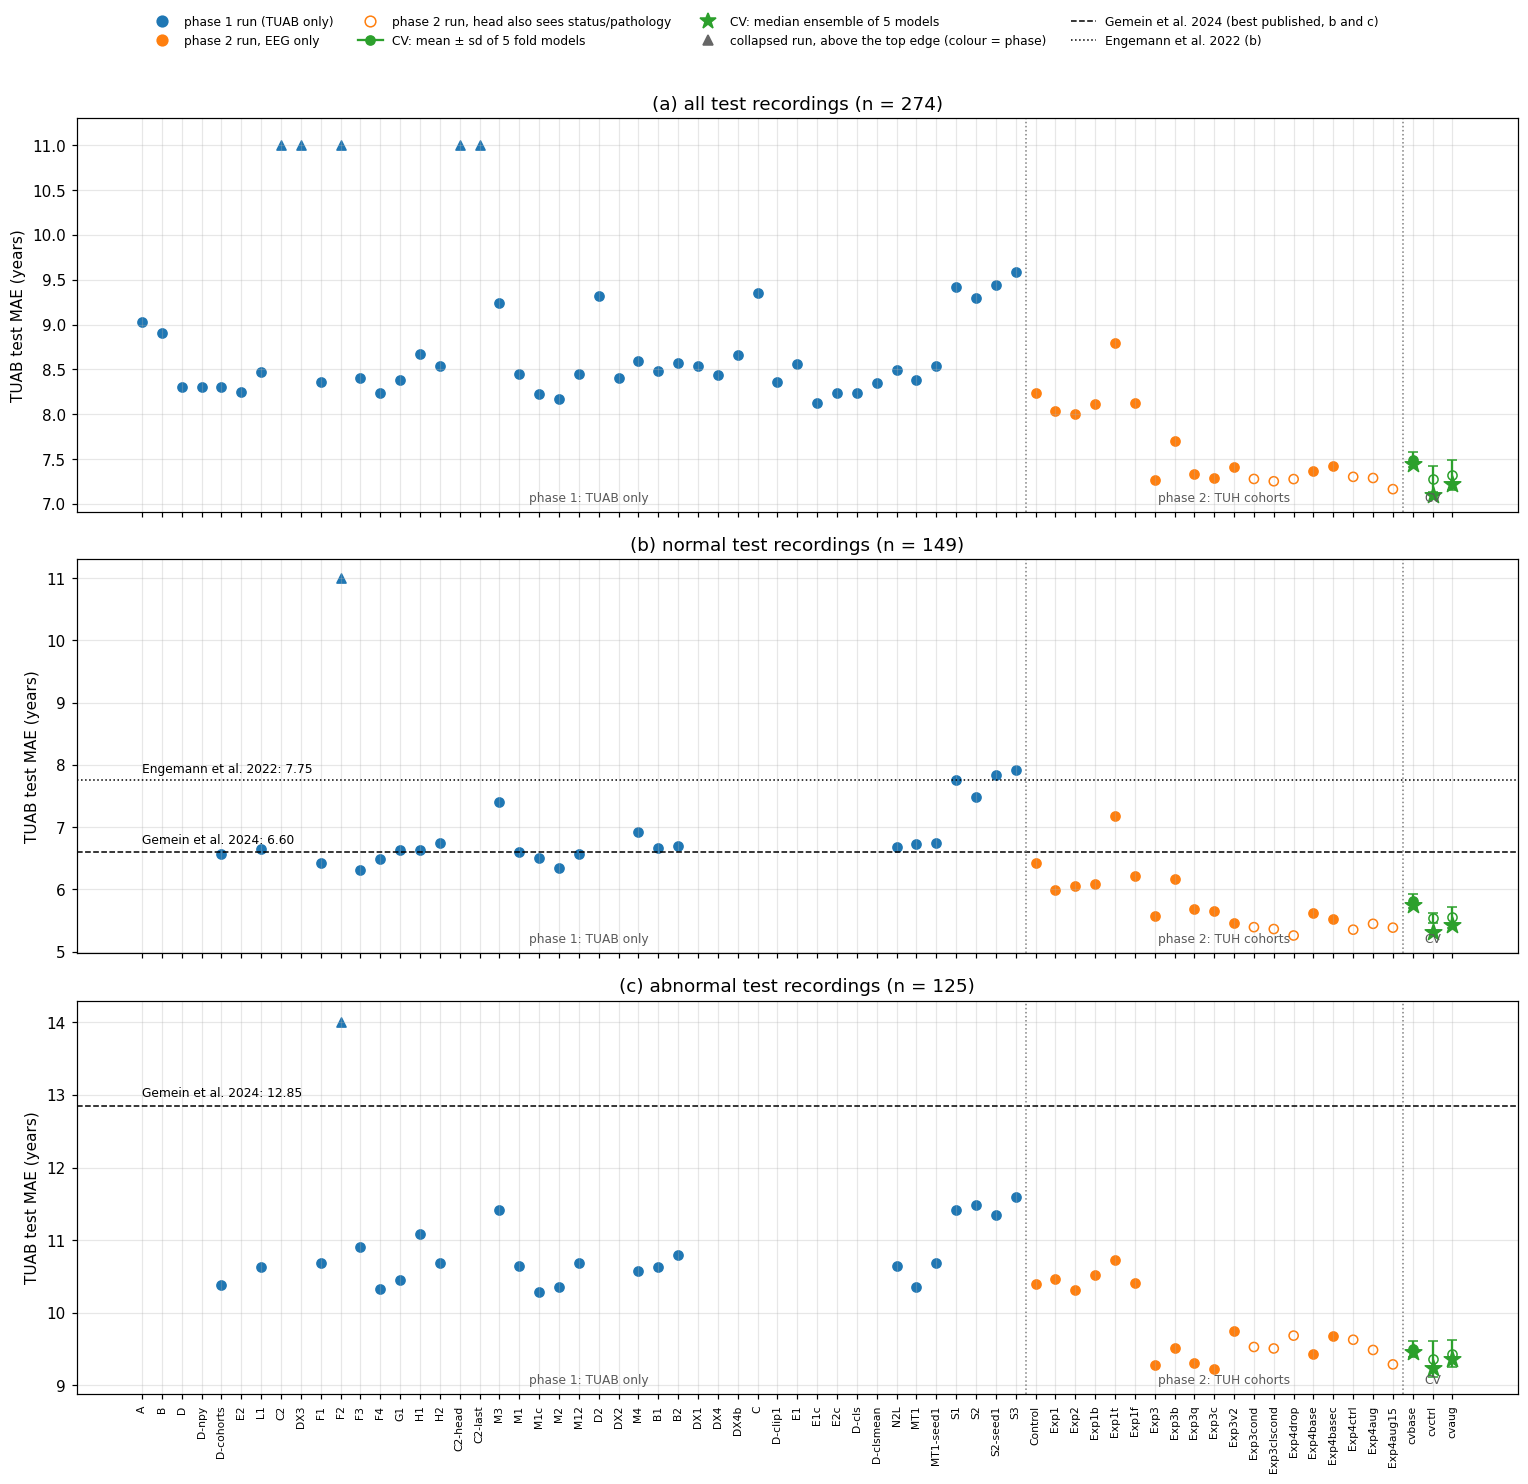

In [15]:
from matplotlib.lines import Line2D

SOTA = {  # published TUAB brain-age MAE (years): (label, value, line style)
    "normal": [("Gemein et al. 2024", 6.60, "--"), ("Engemann et al. 2022", 7.75, ":")],
    "abnormal": [("Gemein et al. 2024", 12.85, "--")],
}
PANELS = (("all", 2, 11.0, "all test recordings (n = 274)"),
          ("normal", 3, 11.0, "normal test recordings (n = 149)"),
          ("abnormal", 4, 14.0, "abnormal test recordings (n = 125)"))
fig, axes = plt.subplots(3, 1, figsize=(14, 13.5), sharex=True)
pts = ([("1", r.run, r.test, r.test_normal, r.test_abnormal, False) for r in reg.itertuples()] +
       [("2", n, t22.loc[n, "test all"], t22.loc[n, "normal"], t22.loc[n, "abnormal"], rs.EXPERIMENTS[n].conditions)
        for n in t22.index])
colors = {"1": "tab:blue", "2": "tab:orange", "3": "tab:green"}
cv_exps = ("cvbase", "cvctrl", "cvaug")
n1 = sum(p[0] == "1" for p in pts)
for ax, (cohort, col, ymax, title) in zip(axes, PANELS):
    for x, p in enumerate(pts):
        y = p[col]
        if np.isnan(y):
            continue
        ax.scatter(x, min(y, ymax), s=36, marker="^" if y > ymax else "o",
                   facecolors="none" if p[5] else colors[p[0]], edgecolors=colors[p[0]])
    for j, exp in enumerate(cv_exps):
        x = len(pts) + j
        m, sd, _ = fold_stats(exp, "heldout", "TUAB", cohort)
        hollow = rs.EXPERIMENTS[exp].conditions
        ax.errorbar(x, m, yerr=sd, fmt="o", color=colors["3"], mfc="none" if hollow else colors["3"], capsize=3)
        if preds is not None and STATUS:
            ax.scatter(x, ens_mae(exp, cohort), marker="*", s=130, color=colors["3"], zorder=3)
    for label, value, ls in SOTA.get(cohort, []):
        ax.axhline(value, ls=ls, color="k", lw=1)
        ax.text(0, value + 0.08, f"{label}: {value:.2f}", fontsize=8, va="bottom")
    for xb in (n1 - 0.5, len(pts) - 0.5):                      # phase separators
        ax.axvline(xb, ls=":", color="0.5", lw=1)
    for xm, label in ((n1 / 2, "phase 1: TUAB only"), ((n1 + len(pts)) / 2, "phase 2: TUH cohorts"),
                      (len(pts) + 1, "CV")):
        ax.text(xm, 0.02, label, transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=8,
                color="0.35")
    ax.set_ylim(top=ymax + 0.3)
    ax.set_ylabel("TUAB test MAE (years)")
    ax.set_title(title)
names = [p[1] for p in pts] + list(cv_exps)
axes[-1].set_xticks(range(len(names)), names, rotation=90, fontsize=7)

dot = dict(marker="o", ls="none", markersize=7)
handles = [
    Line2D([], [], color=colors["1"], mfc=colors["1"], label="phase 1 run (TUAB only)", **dot),
    Line2D([], [], color=colors["2"], mfc=colors["2"], label="phase 2 run, EEG only", **dot),
    Line2D([], [], color=colors["2"], mfc="none", label="phase 2 run, head also sees status/pathology", **dot),
    Line2D([], [], color=colors["3"], mfc=colors["3"], marker="o", ls="-", label="CV: mean ± sd of 5 fold models"),
    Line2D([], [], color=colors["3"], marker="*", ls="none", markersize=11, label="CV: median ensemble of 5 models"),
    Line2D([], [], color="0.4", mfc="0.4", marker="^", ls="none", markersize=7,
           label="collapsed run, above the top edge (colour = phase)"),
    Line2D([], [], color="k", ls="--", lw=1, label="Gemein et al. 2024 (best published, b and c)"),
    Line2D([], [], color="k", ls=":", lw=1, label="Engemann et al. 2022 (b)"),
]
fig.legend(handles=handles, loc="upper center", ncol=4, fontsize=8, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.95))
panel_labels(axes)
assert_max_columns(fig)
plt.show()

### Table 2.5. The runs around the best result

The 12 runs with the lowest TUAB test MAE across all phases (Tables 2.2–2.4):
* `kind`:
  * `single split`: one run;
  * `CV mean`: mean over 5 fold models;
  * `CV ensemble`: median of 5 fold models.
* `cond.`: ✓ if the head is given the status/pathology vector.
* `ClearML`: the run's ClearML experiment (for CV: the project of its folds), linked by its name.
* `test all` / `normal` / `abnormal`: MAE (Eq. (0.1)) on the **TUAB test set only**, all 274 recordings
  and its 149 normal / 125 abnormal ones. The same set is used in every kind of row: for the CV rows it
  is the held-out TUAB test set, which no fold trains on (Table 2.4). The status is TUAB's own
  normal/abnormal label.

Ranked on `test all`, with the best EEG-only run in each kind marked `◆`.

In [16]:
rows = [{"run": r.run, "kind": "single split", "phase": "1", "cond.": "", "test all": r.test,
         "normal": r.test_normal, "abnormal": r.test_abnormal} for r in reg.itertuples()]
rows += [{"run": n, "kind": "single split", "phase": "2", "cond.": "✓" if rs.EXPERIMENTS[n].conditions else "",
          "test all": t22.loc[n, "test all"], "normal": t22.loc[n, "normal"], "abnormal": t22.loc[n, "abnormal"]}
         for n in t22.index]
for exp in ("cvbase", "cvctrl", "cvaug"):
    cond = "✓" if rs.EXPERIMENTS[exp].conditions else ""
    rows.append({"run": exp, "kind": "CV mean", "phase": "3", "cond.": cond,
                 **{k: fold_stats(exp, "heldout", "TUAB", c)[0] for k, c in
                    (("test all", "all"), ("normal", "normal"), ("abnormal", "abnormal"))}})
    if preds is not None and STATUS:
        rows.append({"run": exp, "kind": "CV ensemble", "phase": "3", "cond.": cond,
                     "test all": ens_mae(exp), "normal": ens_mae(exp, "normal"), "abnormal": ens_mae(exp, "abnormal")})
allruns = pd.DataFrame(rows)
top = allruns.sort_values("test all").head(12).copy()
top.insert(1, "ClearML", top.run.map(cml.link))
for kind in top.kind.unique():
    k = allruns[(allruns.kind == kind) & (allruns["cond."] == "")].sort_values("test all")
    if len(k) and k.index[0] in top.index:
        top.loc[k.index[0], "run"] = "◆ " + top.loc[k.index[0], "run"]
numbered_table(top.set_index("run"), "2.5", "The runs around the best result")

,ClearML,kind,phase,cond.,test all,normal,abnormal
run,,,,,,,
cvctrl,tuh_cvctrl_all_both_v3_cvcompact_M1_ep10_cv5-ctrl_cv5,CV ensemble,3,✓,7.10,5.31,9.23
Exp4aug15,tuh_exp4_augT1T2_v3_clscond_ep15_lam0.1_b128_20261015_030018_655,single split,2,✓,7.17,5.38,9.29
cvaug,tuh_cvaug_all_both_v3_cvcompact_M1_ep10_cv5-augT1T2_cv5,CV ensemble,3,✓,7.23,5.43,9.37
Exp3clscond,tuh_exp3clscond_all_both_v2_M1_ep4_cls-cond-status-pathology_20261014_094752_639,single split,2,✓,7.25,5.36,9.51
◆ Exp3,tuh_exp3_all_both_M1_20261012_140234_136,single split,2,,7.26,5.57,9.28
Exp4drop,tuh_exp4_dropT1T2_all_both_v3_cond_M1_ep4_20261014_093428_304,single split,2,✓,7.28,5.26,9.68
Exp3cond,tuh_exp3cond_all_both_v2_M1_ep4_cond-status-pathology_20261013_221741_619,single split,2,✓,7.28,5.39,9.53
cvctrl,tuh_cvctrl_all_both_v3_cvcompact_M1_ep10_cv5-ctrl_cv5,CV mean,3,✓,7.28,5.53,9.37
Exp3c,tuh_exp3c_all_both_M1_ep4_clip800_20261013_103559_425,single split,2,,7.29,5.66,9.22


## 3. The best experiment

**Which run is best.** Single-split runs were compared on the TUAB test set itself (Section 0). Only
the CV runs have an error bar, and their CV test / TUEG out-of-fold errors were never used for
selection. So "best" is decided among the CV runs:

* **Best overall: `cvctrl`** (= Exp4ctrl cross-validated). It has the lowest TUAB test MAE, as a single
  fold model and as a 5-model ensemble (Table 2.4).
  * `cvaug` adds T1/T2 channel-dropout augmentation and ties with it: the differences are within noise
    in Table 5.2 (C2).
  * The simpler `cvctrl` is therefore the recommended configuration.
* **Best EEG-only: `cvbase`.** Its head sees only the EEG. `cvctrl` and `cvaug` also see the
  recording's status (normal / abnormal / no label) and 13 diagnosis flags from the clinical sheet. A
  deployed brain-age model would not have these, and published TUAB results do not use them. `cvbase` is
  therefore the number to compare with the literature (Table 3.3).

Both are LaBraM-base fine-tuned on `all_both_v3` with the M1 recipe. They differ in three settings
(Table 3.2): class-token vs mean pooling, the condition vector, and 10 vs 5 epochs.

### What the model computes

**Input and target.** The raw EEG $u$ (µV) of a 10 s window is scaled to $x = u / 100$ and cut into 1 s
patches $x_{c,a,t}$:
* channel $c = 1..C$, with $C = 23$ minus the missing T1/T2 of that recording;
* patch $a = 1..10$, sample $t = 1..200$.

The common average reference removes what all channels share (`labram/data/preprocess.py::common_average_reference`):

$$ \tilde x_{c,a,t} = x_{c,a,t} - \frac{1}{C}\sum_{c'=1}^{C} x_{c',a,t} \tag{3.1} $$

The age $y$ (years) is z-scored with the training windows' mean $\mu$ and standard deviation $\sigma$
(`labram/data/tuh_datasets.py::TUABAgeLoader._age_target`):

$$ z = \frac{y - \mu}{\sigma} \tag{3.2} $$

**Mixup.** Each training batch is blended with a permuted copy of itself, using one
$\lambda \sim \mathrm{Beta}(\alpha, \alpha)$ per batch with $\alpha = 0.4$ (`labram/train/mixup.py::mixup_batch`).
The condition vector $c$ travels with the target, so it is blended too:

$$ \bar x = \lambda x + (1-\lambda)\,x_{\pi}, \qquad \bar z = \lambda z + (1-\lambda)\,z_{\pi}, \qquad
   \bar c = \lambda c + (1-\lambda)\,c_{\pi} \tag{3.3} $$

**Loss.** Huber loss (Eq. (2.3)) with $\delta = 1$ on the z-scored residual $r = \hat z - \bar z$
(`labram/losses/regression.py::build_regression_criterion`):

$$ \ell_\delta(r) = \begin{cases} \tfrac12 r^2 & \lvert r\rvert \le \delta \\
   \delta\,(\lvert r\rvert - \tfrac12\delta) & \text{otherwise} \end{cases} \tag{3.4} $$

**Encoder and head.** $f_\theta$ is the 12-block LaBraM-base transformer, initialized from the
released `labram-base.pth`. Its output is $h \in \mathbb R^{200}$:
* the final LayerNorm's class token (`cvctrl`, `cvaug`);
* the mean over patch tokens (`cvbase`).

$$ h = f_\theta(\tilde x) \tag{3.5} $$

The linear head reads $h$, concatenated with a 32-d projection of the 17-d condition vector
$c \in \{0,1\}^{17}$ (3 one-hot status + 14 multi-hot pathology groups, `conditions_v1.npz`) when
conditions are on (`labram/models/neural_transformer.py`, `model.session_features=head`):

$$ \hat z = w^\top \begin{bmatrix} h \\ W_c\,c \end{bmatrix} + b, \qquad W_c \in \mathbb R^{32\times 17} \tag{3.6} $$

**Optimizer and schedule.** AdamW with weight decay 0.05. Layer-wise lr decay $\rho = 0.65$ gives block
$l$ of $L = 12$ the rate $\mathrm{lr}\cdot\rho^{\,L+1-l}$ (`labram/optim_factory.py::LayerDecayValueAssigner`).
The rate warms up linearly, then follows a cosine down to $10^{-6}$ (`labram/utils/training.py`).

**Scoring.** A recording's prediction is the de-normalized mean over its evaluation windows $W_i$ (the
first 5 minutes after the trim, 30 windows; `evaluation.agg_windows=mean`):

$$ \hat y_i = \mu + \sigma\,\frac{1}{\lvert W_i\rvert}\sum_{w\in W_i}\hat z_w \tag{3.7} $$

The fold ensemble takes the median over the $K = 5$ fold models (`labram/eval/cv_compare.py::ensemble`):

$$ \hat y_i^{\mathrm{ens}} = \operatorname{median}_{k=1..K}\,\hat y_{i,k} \tag{3.8} $$

### Table 3.1. The best configuration (`cvctrl`), step by step

One row per stage of the pipeline:
* `setting`: the configuration field;
* `cvctrl`: its value, read from the configuration rebuilt by `rs.resolve_config`
  (`finetune_tuab_age.json` + the run's overrides, exactly as the trainer builds it);
* `cvbase`: the EEG-only variant's value, where it differs;
* `equation`: where the setting appears above.

In [17]:
best = rs.resolve_config(AGE_JSON, rs.experiment_overrides(rs.EXPERIMENTS["cvctrl"]))
eeg_only = rs.resolve_config(AGE_JSON, rs.experiment_overrides(rs.EXPERIMENTS["cvbase"]))
paper = rs.resolve_config(PAPER_JSON)
fb, fe = rs.flatten(best.as_dict()), rs.flatten(eeg_only.as_dict())
STEPS = [
    ("data", "cohort", "data.data_path", ""),
    ("data", "5-fold CV, grouped by", "cross_validation.split_by", ""),
    ("data", "CV pool", "cross_validation.pool", ""),
    ("windows", "window length (s)", "data.window_sec", ""),
    ("windows", "trim start / end (s)", ("data.trim_start_sec", "data.trim_end_sec"), ""),
    ("windows", "train minutes per recording per epoch", "data.train_minutes_per_epoch", ""),
    ("windows", "eval minutes per recording", "data.eval_minutes", "(3.7)"),
    ("channels", "channels left out where missing", "channel_drop.channels", ""),
    ("channels", "T1/T2 dropout probability (augmentation)", "channel_drop.prob", ""),
    ("input", "common average reference", "labram_plus.common_average_reference", "(3.1)"),
    ("input", "per-patch z-scoring", "labram_plus.z_score_patches", ""),
    ("encoder", "model", "model.model", "(3.5)"),
    ("encoder", "initial weights", "finetune_checkpoint.finetune", ""),
    ("encoder", "drop path", "model.drop_path", ""),
    ("encoder", "fused attention (speed only)", "model.fused_attention", ""),
    ("head", "mean pooling (False = class token)", "model.use_mean_pooling", "(3.5)"),
    ("head", "condition vector", ("model.session_features", "data.session_features"), "(3.6)"),
    ("head", "condition projection size", "model.session_head_dim", "(3.6)"),
    ("head", "output init scale", "model.init_scale", ""),
    ("target", "task", "model.task", "(3.2)"),
    ("loss", "regression loss / δ", ("loss.regression_loss", "loss.huber_delta"), "(3.4)"),
    ("augmentation", "mixup α (on)", ("mixup.alpha", "mixup.enabled"), "(3.3)"),
    ("optimizer", "AdamW lr / batch", ("optimizer.lr", "trainer.batch_size"), ""),
    ("optimizer", "weight decay / layer decay", ("optimizer.weight_decay", "optimizer.layer_decay"), ""),
    ("schedule", "epochs / warmup", ("trainer.epochs", "optimizer.warmup_epochs"), ""),
    ("schedule", "min lr", "optimizer.min_lr", ""),
    ("selection", "checkpoint", None, "lowest val MAE (recording level)"),
    ("scoring", "window aggregation / case unit", ("evaluation.agg_windows", "evaluation.agg_case_by"), "(3.7)"),
]


def value(flat, keys):
    keys = keys if isinstance(keys, tuple) else (keys,)
    vals = [flat[k] for k in keys]
    vals = [os.path.basename(str(v).rstrip("/")) if k.endswith(("data_path", "finetune")) else v
            for k, v in zip(keys, vals)]
    return " / ".join(rs._show(v) for v in vals)


rows = []
for stage, what, keys, eq in STEPS:
    if keys is None:
        rows.append({"stage": stage, "what": what, "setting": "–", "cvctrl": eq, "cvbase": "", "equation": ""})
        continue
    vb, ve = value(fb, keys), value(fe, keys)
    rows.append({"stage": stage, "what": what, "setting": " / ".join(keys if isinstance(keys, tuple) else (keys,)),
                 "cvctrl": vb, "cvbase": "" if ve == vb else ve, "equation": eq})
numbered_table(pd.DataFrame(rows).set_index(["stage", "what"]), "3.1", "The best configuration")

### Table 3.2. The three cross-validated configurations

Every configuration field on which `cvbase`, `cvctrl` and `cvaug` disagree
(`labram/eval/research_summary.py::config_diff`, bookkeeping fields excluded).

In [18]:
cfgs = {e: rs.flatten(rs.resolve_config(AGE_JSON, rs.experiment_overrides(rs.EXPERIMENTS[e])).as_dict())
        for e in ("cvbase", "cvctrl", "cvaug")}
keys = sorted(k for k in cfgs["cvbase"] if not k.startswith(rs.NON_SCIENTIFIC)
              and len({rs._show(c.get(k)) for c in cfgs.values()}) > 1)
t32 = pd.DataFrame({e: [rs._show(c.get(k)) for k in keys] for e, c in cfgs.items()}, index=pd.Index(keys, name="field"))
numbered_table(t32, "3.2", "The three cross-validated configurations")

,cvbase,cvctrl,cvaug
field,,,
channel_drop.consistency_weight,0,0,0.1
channel_drop.prob,0,0,0.2
data.session_features,,conditions_v1.npz,conditions_v1.npz
model.session_features,off,head,head
model.use_mean_pooling,True,False,False
optimizer.warmup_epochs,1,3,3
trainer.epochs,5,10,10


### Table 3.3. Results of the best experiment by evaluation set and cohort

`cvctrl` (best overall) and `cvbase` (best EEG-only), mean ± sample sd over the 5 fold models of the
MAE (Eq. (0.1)) and the mean $R^2$ (Eq. (0.2)), per evaluation set and status cohort:
* `CV val`, `CV test`: the fold's own held-out folds, TUAB and TUEG recordings together;
* `TUEG test`: the TUEG recordings of each fold's test fold;
* `TUAB test`: the official test set, $n = 274$.

$R^2$ is relative to each cohort's own age spread, so it does not compare across cohorts. The last row
gives the median ensemble (Eq. (3.8)) on the TUAB test set when the per-recording predictions are
available. For reference, the best published TUAB normal-recording result is MAE 6.60, $R^2$ 0.73
(Gemein et al. 2024, trained on TUAB normal recordings only, on its own patient-wise re-split of TUAB).

In [19]:
rows = []
for label, split, source in (("CV val", "val", "all"), ("CV test", "test", "all"), ("TUEG test", "test", "TUEG"),
                             ("TUAB test", "heldout", "TUAB")):
    for cohort in ("all", "normal", "abnormal"):
        r = {"set": label, "cohort": cohort}
        for exp in ("cvctrl", "cvbase"):
            s = cv[(cv.exp == exp) & (cv.split == split) & (cv.source == source) & (cv.cohort == cohort)]
            s = s.drop_duplicates("fold")
            r[f"{exp} MAE"] = f"{s.MAE.mean():.2f} ± {s.MAE.std(ddof=1):.2f}"
            r[f"{exp} R²"] = round(float(s.R2.mean()), 2)
        rows.append(r)
if preds is not None and STATUS:
    for cohort in ("all", "normal", "abnormal"):
        r = {"set": "TUAB test, ensemble", "cohort": cohort}
        for exp in ("cvctrl", "cvbase"):
            e = ensemble(exp)
            e = e if cohort == "all" else e[e.status == cohort]
            m = cc.metrics(e.pred, e.true)
            r[f"{exp} MAE"] = f"{m['MAE']:.2f}"
            r[f"{exp} R²"] = round(m["R2"], 2)
        rows.append(r)
numbered_table(pd.DataFrame(rows).set_index(["set", "cohort"]), "3.3", "Results of the best experiment")

### Table 3.4. Predicted versus true age by subcohort and status

The three cross-validated models, scored per recording on three sets of recordings
(`rs.prediction_sets`, from the per-recording CV predictions):
* `TUAB test, ensemble`: the 274 TUAB test recordings, predicted by the median of the 5 fold models
  (Eq. (3.8)).
* `TUAB out-of-fold`: the TUAB recordings of the CV pool (TUAB train + val), each predicted by the one fold
  model that never saw its patient.
* `TUEG out-of-fold`: the same for the pool's TUEG recordings that are not in TUAB.

`status` is the recording's normal / abnormal / no-label status (Eq. (1.2)), and `all` is every
recording of the set. Per model, the columns are:
* `MAE` (Eq. (0.1), years);
* `bias` = mean(predicted − true) (Eq. (0.3), years): the signed drift. It is negative when the model
  predicts too young and positive when too old, so closer to 0 is better;
* $R^2$ (Eq. (0.2));
* the bias slope $\beta$ (Eq. (0.5)).

All come from `rs.prediction_metrics`. Needs the
per-recording CV predictions and the TUH index.

In [20]:
if preds is not None and HAVE_TUEG:
    psets = rs.prediction_sets(preds, tueg)
    pm = rs.prediction_metrics(psets)
    t34 = pm.pivot_table(index=["set", "status"], columns="exp", values=["MAE", "bias", "R²", "β"], sort=False)
    t34 = t34.swaplevel(axis=1).reindex(columns=pd.MultiIndex.from_product([cv_exps, ["MAE", "bias", "R²", "β"]]))
    n = pm.drop_duplicates(["set", "status"]).set_index(["set", "status"]).n
    t34.insert(0, ("", "n"), n.reindex(t34.index))
    order = {s: k for k, s in enumerate(rs.PREDICTION_SETS)}
    t34 = t34.sort_index(key=lambda ix: ix.map(order) if ix.name == "set" else
                         ix.map({s: k for k, s in enumerate(("all", *rs.STATUS))}))
    display(numbered_table(t34, "3.4", "Predicted versus true age by subcohort and status"))
else:
    print("Per-recording CV predictions or the TUH index not found: Table 3.4 and Figure 3.1 skipped.")

### Figure 3.1. Predicted versus true age, per model and subcohort

Predicted age $\hat y_i$ against true age $y_i$ (years), one point per recording; the data of Table 3.4.
One row per cross-validated model, and two subcohorts per row:
* left column: the 274 TUAB test recordings, predicted by the 5-model median ensemble;
* right column: the TUEG out-of-fold recordings ($n$ = 26,685), each predicted by the fold model that
  held it out.

The panels are:
* (a), (b) `cvbase`, the best EEG-only model;
* (c), (d) `cvctrl`, the best overall;
* (e), (f) `cvaug`.

**Colour = status** (Eq. (1.2)): green normal, red abnormal, grey no label. The no-label group occurs only
in TUEG.
* **Dashed black diagonal:** a perfect prediction, $\hat y = y$.
* **Coloured lines:** least-squares fits of $\hat y$ on $y$ per status. A fit flatter than the diagonal
  is the regression to the mean that $\beta$ measures: the fit's slope is $1 + \beta$ (Eq. (0.5)).
* **Box in each panel:** $n$, MAE and $\beta$ per status, and for all recordings together.

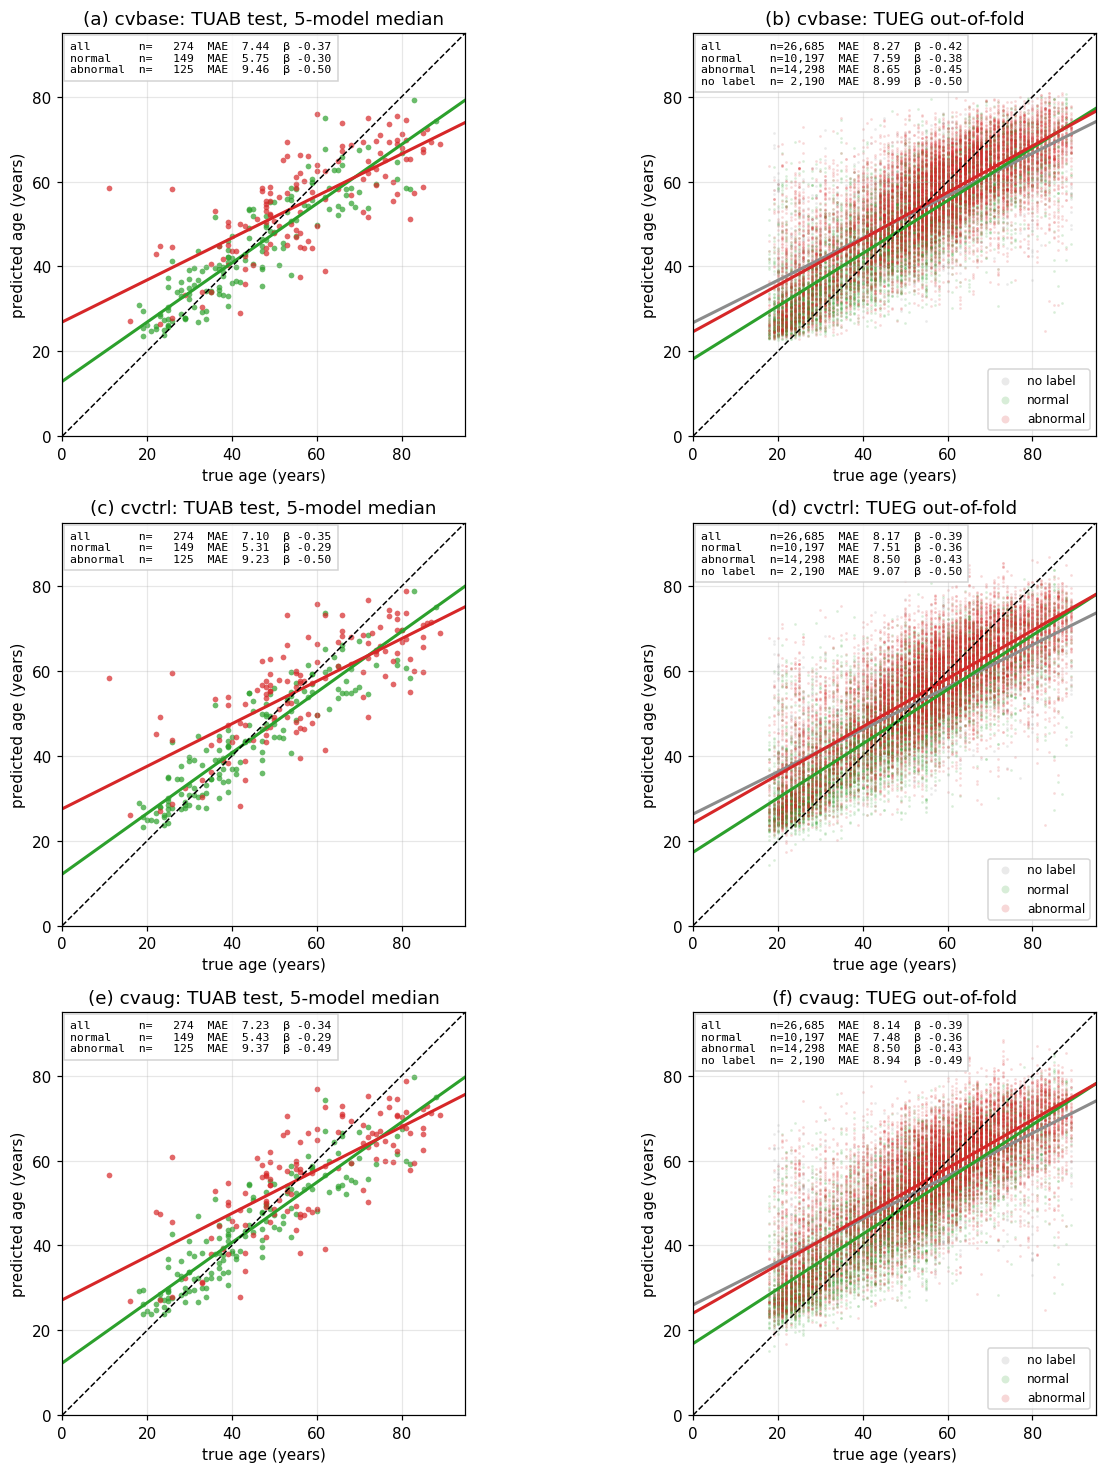

In [21]:
if preds is not None and HAVE_TUEG:
    SCOL = {"normal": "tab:green", "abnormal": "tab:red", "no label": "0.55"}
    shown = (rs.PREDICTION_SETS[0], rs.PREDICTION_SETS[2])
    fig, axes = plt.subplots(len(cv_exps), 2, figsize=(12.5, 4.5 * len(cv_exps)))  # fits one PDF page
    grid = np.linspace(0, 95, 2)
    for r, exp in enumerate(cv_exps):
        for c, name in enumerate(shown):
            ax = axes[r, c]
            g = psets[(psets.exp == exp) & (psets.set == name)]
            big = len(g) > 2000
            lines = []
            for status in ("no label", "normal", "abnormal"):          # abnormal drawn last, on top
                s = g[g.status == status]
                if not len(s):
                    continue
                ax.scatter(s.true, s.pred, s=3 if big else 14, alpha=0.18 if big else 0.7, color=SCOL[status],
                           lw=0, rasterized=True, label=status)
                k, b = np.polyfit(s.true, s.pred, 1)
                ax.plot(grid, k * grid + b, color=SCOL[status], lw=2)
            for status in ("all", "normal", "abnormal", "no label"):
                s = g if status == "all" else g[g.status == status]
                if len(s):
                    m = rs.age_fit_metrics(s.pred, s.true)
                    lines.append(f"{status:9s} n={m['n']:>6,}  MAE {m['MAE']:5.2f}  β {m['β']:+.2f}")
            ax.plot(grid, grid, ls="--", color="k", lw=1)
            ax.text(0.02, 0.98, "\n".join(lines), transform=ax.transAxes, va="top", ha="left", fontsize=7.5,
                    family="monospace", bbox=dict(facecolor="white", alpha=0.85, edgecolor="0.8"))
            ax.set_xlim(0, 95)
            ax.set_ylim(0, 95)
            ax.set_aspect("equal")
            ax.set_xlabel("true age (years)")
            ax.set_ylabel("predicted age (years)")
            what = "TUAB test, 5-model median" if c == 0 else "TUEG out-of-fold"
            ax.set_title(f"{exp}: {what}")
            if c == 1:
                ax.legend(loc="lower right", fontsize=8, markerscale=3)
    fig.tight_layout()
    panel_labels(list(axes.ravel()))
    assert_max_columns(fig)
    plt.show()

**Reading Table 3.4 and Figure 3.1.**
* **Abnormal recordings are harder in every set.**
  * On TUAB test, their MAE is 3.7–3.9 years above the normal recordings'.
  * In TUEG out-of-fold the gap is about 1 year (0.99–1.06). The no-label recordings are the hardest there
    (MAE 8.9–9.1).
* **Every model regresses to the mean** ($\beta \approx -0.3$ to $-0.5$). The fit lines in Figure 3.1
  are visibly flatter than the diagonal: old patients are predicted too young and young ones too old.
  The effect is strongest for the abnormal and no-label recordings ($\beta \approx -0.43$ to $-0.50$).
* **Bias.** The overall drift is small: within ±1.2 years on TUAB test and ±0.3 on TUEG. But the
  EEG-only `cvbase` predicts abnormal TUAB test recordings 2.0 years too young on average, against
  0.9–1.0 for `cvctrl` / `cvaug`.
* **TUEG is harder than TUAB.** TUEG out-of-fold MAE is 8.1–8.3, against 7.1–7.2 for the TUAB recordings
  of the same pool. Its normal recordings are worse too: 7.5–7.6 against 6.4–6.6. TUEG's status comes
  from report text rather than TUAB's curated folders. It also covers a broad clinical population: 38 %
  of its recordings in the clinical sheet list a sedating drug (Table 1.6).
* **cvctrl and cvaug beat cvbase on the TUAB test ensemble** by 0.2–0.35 years. Their gain is larger on
  normal recordings (0.3–0.4 years) than on abnormal ones (0.1–0.2).

### Table 3.5. TUAB test MAE before and after age-bias correction

**Every other number in this notebook is before bias correction.** That includes the MAEs of Sections 0–5
and Figure 2.1. They score the model's raw prediction $\hat y_i$. Brain-age studies often also report a
*bias-corrected* error. Gemein et al. 2024 does: its 6.60 / 12.85 are after correction, and its raw
normal MAE was 6.48. This table puts our CV models on that footing.

**The correction.** Per experiment, fit the brain-age gap as a polynomial $p$ of the true age on the
experiment's own **out-of-fold** predictions. These are CV-pool recordings, never the TUAB test set.
Then subtract the fit from each test prediction (`rs.bias_corrected_test`):

$$ e_i = \hat y_i - y_i \approx p(y_i), \qquad \hat y^{c}_i = \hat y_i - p(y_i) \tag{3.9} $$

* **Degree:** $p$ is linear or quadratic. Gemein et al. use a quadratic.
* **Fit data:** either all out-of-fold recordings, or only the normal ones (as Gemein et al., whose
  model only ever saw normal recordings).
* **Caveat:** Eq. (3.9) uses each test recording's **true age** $y_i$. The corrected error therefore
  measures the brain-age gap after removing its age trend. It is not the error a deployed model would
  make, since a deployed model does not know the age it predicts.

**Columns.** The MAE of the TUAB test ensemble (Eq. (0.1)) per model and status:
* `raw`: no correction (as in Table 3.4);
* `lin, all` / `quad, all`: Eq. (3.9), linear or quadratic, fitted on all out-of-fold recordings;
* `quad, normal`: quadratic, fitted on the normal out-of-fold recordings only;
* `bias, quad normal`: the mean gap (Eq. (0.3)) after that correction. A positive value means the
  recordings look older than they are.

The last rows give Gemein et al. 2024 for reference.

In [22]:
if preds is not None and HAVE_TUEG:
    variants = {"raw": psets[psets.set == rs.PREDICTION_SETS[0]],
                "lin, all": rs.bias_corrected_test(psets, 1),
                "quad, all": rs.bias_corrected_test(psets, 2),
                "quad, normal": rs.bias_corrected_test(psets, 2, fit_status=("normal",))}
    rows = []
    for exp in cv_exps:
        for status in ("all", "normal", "abnormal"):
            r = {"model": exp, "status": status}
            for name, d in variants.items():
                g = d[d.exp == exp]
                g = g if status == "all" else g[g.status == status]
                m = rs.age_fit_metrics(g.pred, g.true)
                r[name] = m["MAE"]
                if name == "quad, normal":
                    r["bias, quad normal"] = m["bias"]
            rows.append(r)
    rows += [{"model": "Gemein et al. 2024", "status": "normal", "raw": 6.48, "quad, normal": 6.60},
             {"model": "Gemein et al. 2024", "status": "abnormal", "quad, normal": 12.85}]
    t35 = pd.DataFrame(rows).set_index(["model", "status"])
    display(numbered_table(t35, "3.5", "TUAB test MAE before and after age-bias correction"))

**Reading Table 3.5.**
* **Normal recordings.** Correction changes little when it is fitted on all recordings (5.3–5.8 raw,
  5.4–5.7 corrected). With Gemein's choice, a quadratic fitted on normal recordings, the normal MAE
  falls to 4.6–4.8 years, against Gemein's 6.60 after the same kind of correction.
* **Abnormal recordings.** Correction removes most of their error: 9.2–9.5 raw becomes 6.4–7.0. Much of
  the raw abnormal error is regression to the mean ($\beta \approx -0.5$, Table 3.4), and Eq. (3.9)
  undoes it with the true age.
* **Abnormal recordings look older.** After the normal-fit correction they keep a positive gap of
  +1.8 to +3.0 years (`bias, quad normal`), and normal recordings a negative one. This is the
  brain-age-gap effect Gemein et al. report: −4 years between normal and pathological subjects.
* **Ranking.** All three models are within 0.35 years of each other after correction.
* **Conclusion.** The raw numbers used throughout the notebook are the conservative ones. The
  corrected numbers are only comparable with published bias-corrected results, such as the 6.60.

### Table 3.6. Agreement between experiments on the TUAB test set

How similar are the models' predictions, recording by recording? The comparison covers two kinds of
pair:
* every pair of experiment ensembles (cvbase / cvctrl / cvaug);
* as a reference, the 10 pairs of fold models *within* each experiment. These pairs share the
  configuration but differ in training data and seed.

For two predictors $a$ and $b$ on the same recordings, with errors $e^a_i = \hat y^a_i - y_i$
(`labram/eval/cv_compare.py::pairwise`):

$$ \mathrm{agree}_\tau = \frac{1}{n}\sum_i \mathbb 1\big[\lvert \hat y^a_i - \hat y^b_i\rvert \le \tau\big], \qquad
   \mathrm{sign} = \frac{1}{n}\sum_i \mathbb 1\big[\operatorname{sgn} e^a_i = \operatorname{sgn} e^b_i\big] \tag{3.10} $$

Columns, per status (all 274, normal 149, abnormal 125):
* `r_pred`, `r_err`: the Pearson correlation of the two models' predictions and of their errors.
  `r_err` near 1 means they make the same mistakes on the same recordings.
* `agree_2y`, `agree_5y`: $\mathrm{agree}_\tau$ for $\tau$ = 2 and 5 years.
* `sign_agree`: Eq. (3.10, right). The share of recordings where both models err in the same direction
  (both predict too old, or both too young).
* `dMAE`: $\mathrm{MAE}_a - \mathrm{MAE}_b$ (Eq. (0.4)) for an ensemble pair; the mean $\lvert\Delta\mathrm{MAE}\rvert$
  over the 10 pairs for a fold-model row.

In [23]:
if preds is not None and HAVE_TUEG:
    wide = rs.test_predictors(preds)
    test_true = preds[preds.split == "heldout"].groupby("stem").true.first()
    test_status = tueg.drop_duplicates("stem").set_index("stem").status
    t36 = rs.agreement_summary(wide, test_true, test_status, cv_exps).set_index(["status", "pair"])
    display(numbered_table(t36, "3.6", "Agreement between experiments on the TUAB test set", precision=3))

### Figure 3.2. Error correlation between all TUAB-test predictors

The Pearson correlation of the errors $e_i = \hat y_i - y_i$ between every pair of the 18 predictors of
the TUAB test set: each experiment's 5 fold models (`f0`–`f4`) and its median ensemble (`ens`).
* (a) The 149 normal recordings.
* (b) The 125 abnormal recordings.

The colour scale runs from 0.85 (lighter) to 1 (darker). The thin white lines separate the three
experiments.

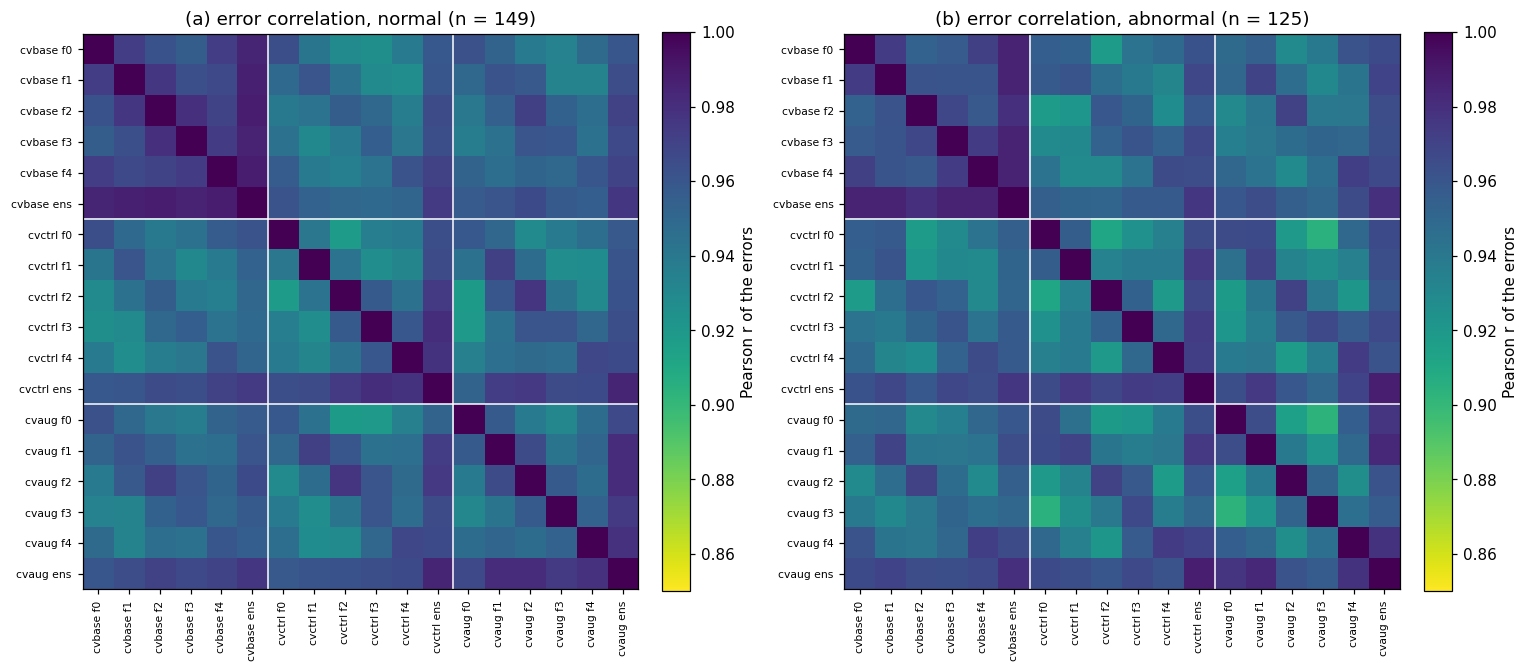

In [24]:
if preds is not None and HAVE_TUEG:
    fig, axes = plt.subplots(1, 2, figsize=(14, 6.4))
    err = wide.sub(test_true.loc[wide.index], axis=0)
    for ax, status in zip(axes, ("normal", "abnormal")):
        idx = wide.index[test_status.loc[wide.index] == status]
        r = err.loc[idx].corr()
        im = ax.imshow(r.to_numpy(), vmin=0.85, vmax=1.0, cmap="viridis_r")
        ax.set_xticks(range(len(r)), r.columns, rotation=90, fontsize=7)
        ax.set_yticks(range(len(r)), r.index, fontsize=7)
        for k in (6, 12):
            ax.axhline(k - 0.5, color="w", lw=1)
            ax.axvline(k - 0.5, color="w", lw=1)
        ax.grid(False)
        ax.set_title(f"error correlation, {status} (n = {len(idx)})")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Pearson r of the errors")
    fig.tight_layout()
    panel_labels(list(axes))
    assert_max_columns(fig)
    plt.show()

### Figure 3.3. Per-recording agreement of the three experiments

TUAB test recordings, coloured by status: green normal, red abnormal. Errors $e = \hat y - y$ are in
years.
* (a)–(c) The error of one experiment's ensemble against another's, for each pair of experiments. A
  point on the dashed diagonal means both models made the same error. A point in the upper-right or
  lower-left quadrant means both erred in the same direction.
* (d) **Disagreement per recording:** the sample standard deviation of the 15 fold models'
  predictions (3 experiments × 5 folds), against the true age.

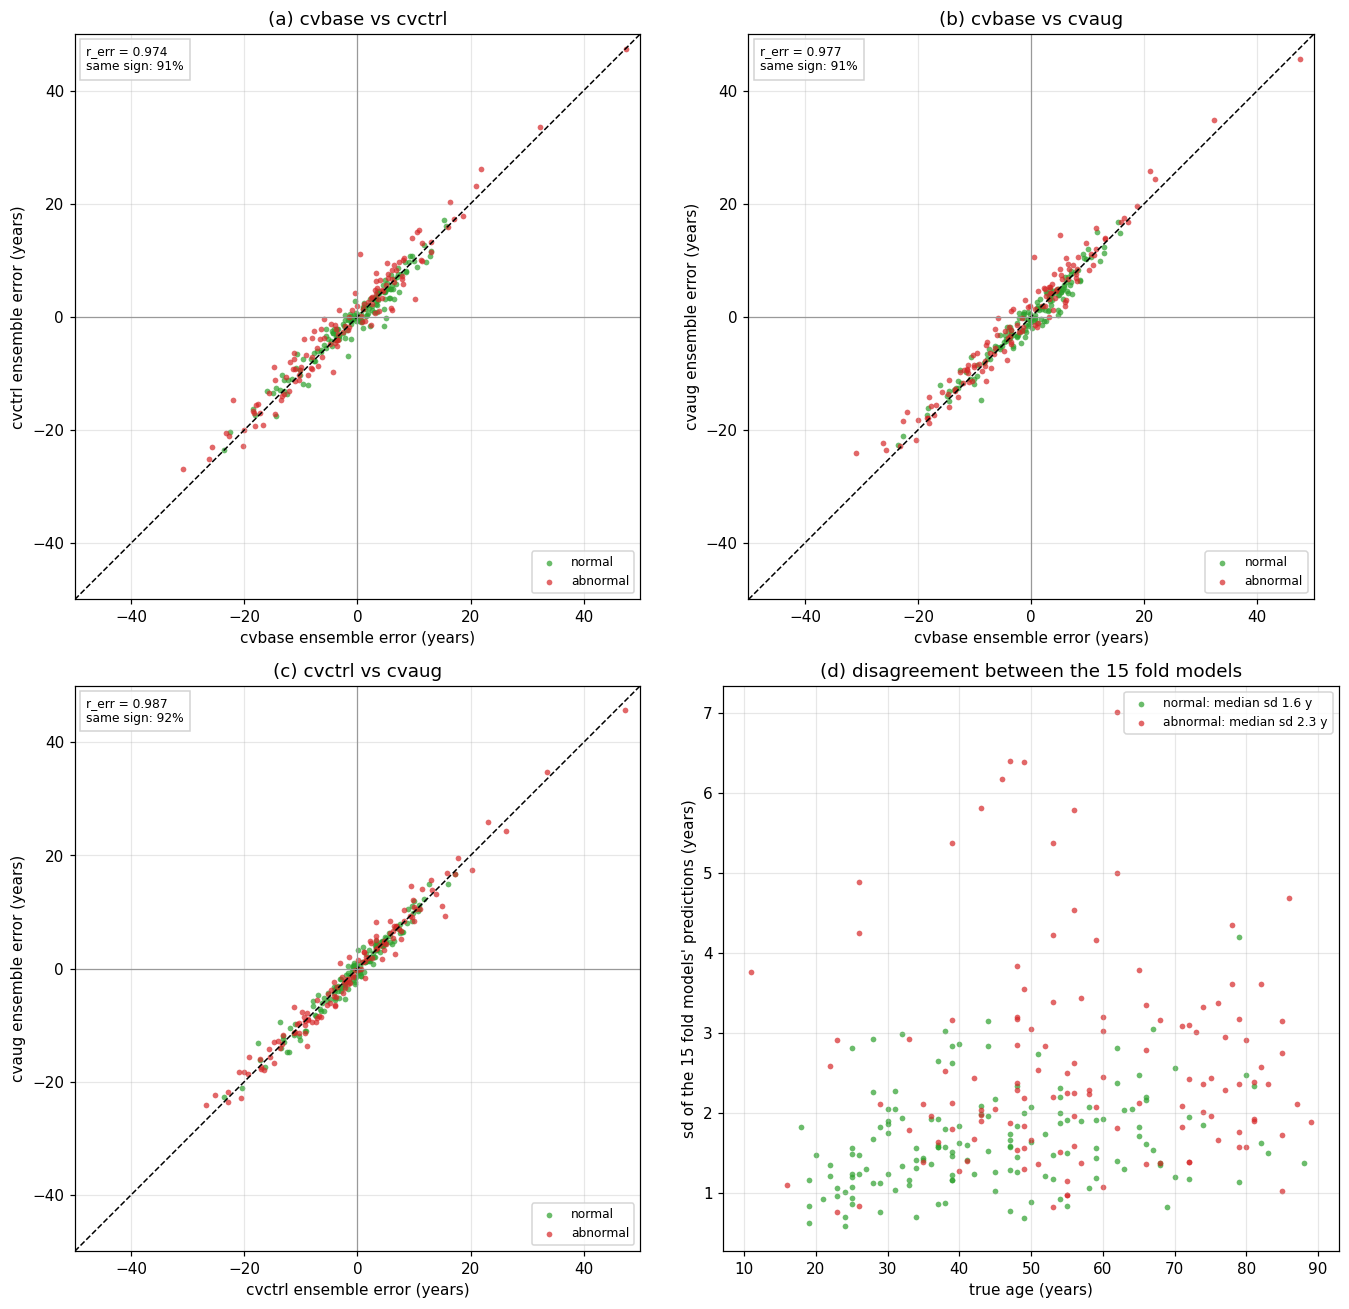

In [25]:
if preds is not None and HAVE_TUEG:
    SCOL = {"normal": "tab:green", "abnormal": "tab:red"}
    fig, axes = plt.subplots(2, 2, figsize=(12.5, 12))
    pairs = [("cvbase", "cvctrl"), ("cvbase", "cvaug"), ("cvctrl", "cvaug")]
    st = test_status.loc[wide.index]
    for ax, (a, b) in zip(axes.ravel()[:3], pairs):
        ea, eb = err[f"{a} ens"], err[f"{b} ens"]
        for status, col in SCOL.items():
            m = st == status
            ax.scatter(ea[m], eb[m], s=14, alpha=0.7, color=col, lw=0, label=status)
        lim = float(np.ceil(max(ea.abs().max(), eb.abs().max()) / 5) * 5)
        ax.plot([-lim, lim], [-lim, lim], ls="--", color="k", lw=1)
        ax.axhline(0, color="0.6", lw=0.8)
        ax.axvline(0, color="0.6", lw=0.8)
        ax.set_xlim(-lim, lim)
        ax.set_ylim(-lim, lim)
        ax.set_aspect("equal")
        r = float(np.corrcoef(ea, eb)[0, 1])
        ax.text(0.02, 0.98, f"r_err = {r:.3f}\nsame sign: {np.mean(np.sign(ea) == np.sign(eb)):.0%}",
                transform=ax.transAxes, va="top", fontsize=8,
                bbox=dict(facecolor="white", alpha=0.85, edgecolor="0.8"))
        ax.set_xlabel(f"{a} ensemble error (years)")
        ax.set_ylabel(f"{b} ensemble error (years)")
        ax.set_title(f"{a} vs {b}")
        ax.legend(loc="lower right", fontsize=8)
    ax = axes[1, 1]
    folds = wide[[c for c in wide.columns if " f" in c]]
    spread = folds.std(axis=1, ddof=1)
    for status, col in SCOL.items():
        m = st == status
        ax.scatter(test_true.loc[wide.index][m], spread[m], s=14, alpha=0.7, color=col, lw=0,
                   label=f"{status}: median sd {spread[m].median():.1f} y")
    ax.set_xlabel("true age (years)")
    ax.set_ylabel("sd of the 15 fold models' predictions (years)")
    ax.set_title("disagreement between the 15 fold models")
    ax.legend(fontsize=8)
    fig.tight_layout()
    panel_labels(list(axes.ravel()))
    assert_max_columns(fig)
    plt.show()

**Reading Table 3.6 and Figures 3.2 and 3.3.**
* **The three experiments make almost the same errors.** Their ensembles' errors correlate at
  r = 0.974–0.987 (Figure 3.2, Figure 3.3(a)–(c)). On 91–92 % of the recordings both err in the same
  direction, and on 96–99 % they predict within 5 years of each other. The differences in MAE between
  them (Table 2.4) come from small shifts, not from different recordings going wrong.
* **The ensembles agree more than single fold models do.** The ensemble pairs agree more closely across
  experiments (r_err 0.97–0.99, within 2 years on 69–82 % of recordings) than two fold models of the same
  experiment (r_err 0.94–0.97, 52–67 %). Averaging five models removes much of the fold-to-fold noise,
  which is why the ensemble beats a single model (Table 5.2, C3).
* **Abnormal recordings: shared errors, more disagreement.** The models agree on the error direction
  more often on abnormal recordings: 93–96 % same sign, against 89–90 % on normal ones. But their
  predictions spread more there, with fewer abnormal recordings within 2 years (56–73 %, against
  81–90 %). The fold models also disagree more on abnormal recordings (Figure 3.3(d)).
* **The largest errors are shared.** In Figure 3.3(a)–(c), the points far from the origin lie near the
  diagonal: the recordings that one model gets badly wrong, all models get badly wrong. Of the 20
  largest `cvctrl` test errors, 16 are abnormal recordings (46 % of the test set is abnormal), and
  17 are patients under 30 or over 70. These recordings are the main lever left for improving the
  MAE.

## 4. Changes versus the LaBraM recipe

The reference is **LaBraM as published for TUAB**, `labram/configs/defaults/finetune_tuab_paper.json`:
* LaBraM-base fine-tuned for normal/abnormal classification, the recipe of the paper and the README;
* lr $5\cdot10^{-4}$, batch 64, 50 epochs with 5 warmup, layer decay 0.65, drop path 0.1;
* no input re-referencing;
* a 50 Hz notch in preprocessing (`dataset_maker/make_TUAB.py`).

Table 4.1 lists every configuration field the best configuration changes. Table 4.2 lists the changes
that live in the data or the code rather than the configuration. Section 5 then tests which of them
moved the error.

### Table 4.1. Configuration changes: LaBraM TUAB recipe → best configuration

Every field on which `finetune_tuab_paper.json` and `cvctrl` (Table 3.1) differ, computed by
`labram/eval/research_summary.py::config_diff`. Excluded:
* bookkeeping fields (paths, logging, infrastructure);
* fields a regression run never reads (`INERT_FOR_REGRESSION`);
* fields of a section that is off in both.

Columns:
* `group`: the part of the pipeline;
* `meaning`: what the change does;
* `evidence`: the rows of Table 5.2 that test it, where one does.

In [26]:
MEANING = {
    "data.dataset": ("task", "age regression on TUH (TUAB_AGE loader) instead of normal/abnormal", ""),
    "data.data_format": ("data", "storage only: one float32 npy per recording, windows bit-identical to the pickles", ""),
    "model.task": ("task", "scalar regression head (Huber on z-scored age, Eqs. (3.2), (3.4))", ""),
    "labram_plus.enabled": ("input", "turns on the LaBraM++ input block (Eq. (3.1))", "P1"),
    "labram_plus.z_score_patches": ("input", "LaBraM++ block with CAR only, no per-patch z-scoring", "P1"),
    "data.trim_start_sec": ("windows", "drop the first 60 s of every recording", ""),
    "data.trim_end_sec": ("windows", "drop the last 60 s of every recording", ""),
    "data.eval_minutes": ("windows", "score each recording on its first 5 minutes after the trim", "P26"),
    "data.train_minutes_per_epoch": ("windows", "5 minutes per recording per epoch, redrawn each epoch (speed)", "Q14"),
    "evaluation.agg_windows": ("scoring", "one prediction per recording = mean of its windows (Eq. (3.7))", ""),
    "mixup.enabled": ("augmentation", "mixup α 0.4 (Eq. (3.3))", "P3"),
    "optimizer.lr": ("optimizer", "2e-4 at batch 128 = 1e-4 at batch 64, linearly scaled", "Q14"),
    "trainer.batch_size": ("optimizer", "batch 128 (speed; lr scaled with it)", "Q14"),
    "optimizer.warmup_epochs": ("schedule", "3 warmup epochs", "P2, Q6, C1"),
    "trainer.epochs": ("schedule", "10 epochs instead of 50 (best epoch is early)", "P2, Q6, C1"),
    "model.use_mean_pooling": ("head", "head on the class token instead of the mean patch token", "P22, Q13, C1"),
    "model.session_features": ("head", "status + pathology vector concatenated to the feature (Eq. (3.6))", "Q12, C1"),
    "data.session_features": ("head", "the condition vectors' file (conditions_v1.npz)", "Q12, C1"),
    "channel_drop.enabled": ("channels", "per-sample handling of missing T1/T2 (needed for cohort v3)", "Q14"),
    "channel_drop.channels": ("channels", "T1/T2 are the channels that may be missing", "Q14"),
    "channel_drop.max_drop": ("channels", "up to both of T1/T2", "Q14"),
    "channel_drop.prob": ("channels", "0: no channel-dropout augmentation in cvctrl", "Q17, C2"),
    "channel_drop.consistency_weight": ("channels", "0: no consistency loss in cvctrl", "Q17, C2"),
    "cross_validation.enabled": ("protocol", "5-fold patient-grouped cross-validation", "C3"),
    "model.fused_attention": ("speed", "fused attention kernel, numerically the same model", ""),
}
t41 = rs.config_diff(paper, best, ("LaBraM recipe", "best (cvctrl)"),
                     ignore=rs.NON_SCIENTIFIC + rs.INERT_FOR_REGRESSION)
t41["group"] = t41.field.map(lambda f: MEANING.get(f, ("?", "", ""))[0])
t41["meaning"] = t41.field.map(lambda f: MEANING.get(f, ("", "(not annotated)", ""))[1])
t41["evidence"] = t41.field.map(lambda f: MEANING.get(f, ("", "", ""))[2])
missing = sorted(set(t41.field) - set(MEANING))
assert not missing, f"annotate these fields in MEANING: {missing}"
t41 = t41.sort_values(["group", "field"]).set_index(["group", "field"])
numbered_table(t41, "4.1", "Configuration changes versus the LaBraM TUAB recipe")

### Table 4.2. Changes outside the configuration

Changes in the training data, the preprocessing, the split and the code, with the Table 5.2 rows that
test them.

| change | LaBraM recipe | this study | evidence |
|---|---|---|---|
| training data | TUAB train, 2,145 recordings (≈1.6k patients) | TUAB + TUEG, 25,613 recordings (≈12k patients, `all_both_v3`) | Q1, Q3 |
| mains interference | 50 Hz notch (TUH is recorded at 60 Hz, so the line stays in) | 50 + 60 Hz spectrum interpolation | L1 |
| channels | 23 fixed channels | 23; TUEG recordings missing only T1/T2 kept, with those channels left out per sample | Q14 |
| validation split | TUAB's train split, which leaks 16 patients between train and val | patient-disjoint, seeded; one TUEG patient split shared by all cohorts; TUAB-test patients removed from TUEG | Q11 |
| label | normal/abnormal | age from the EDF header (18–89 in the TUH cohorts) | – |
| unit of evaluation | 10 s window | recording (Eq. (3.7)), first 5 minutes after the trim | P26 |
| per-patient cap | none | at most 10 train/val recordings per patient | – |
| reported model | one run | median of 5 fold models (Eq. (3.8)) | C3 |
| reproducibility | ClearML silently reseeded every tracked run to 1337 | fixed: `distributed.seed` is honoured (commit `7b9a5fe`) | – |

## 5. Which changes mattered

**Noise floor.** Two runs of the same configuration with different seeds do not give the same MAE. The
line-removal A/B study ran each of 3 preprocessing recipes $r$ with 3 seeds $s$, and each run is read
at its best-validation epoch. The pooled within-recipe sample standard deviation of a metric $m$
(`labram/eval/research_summary.py::seed_noise`) is

$$ \hat\sigma_m^2 = \frac{1}{N - R}\sum_{r}\sum_{s}\big(m_{r,s} - \bar m_r\big)^2 \tag{5.1} $$

with $N = 9$ runs and $R = 3$ recipes.

**Significance rule.** Each row of Table 5.2 compares a baseline with a variant that changes one thing
(or a named bundle), using whichever evidence exists:

* **One run each** (phases 1 and 2). The difference of two single runs has standard deviation
  $\sqrt2\,\hat\sigma$, so a change counts only if (`rs.pair_threshold`)

  $$ \lvert\Delta\mathrm{MAE}\rvert > \tau = 1.96\,\sqrt2\,\hat\sigma_{\text{test}}. \tag{5.2} $$

* **Three seeds each** (line removal, L1/L2):

  $$ \lvert \bar\Delta \rvert > 1.96\,\hat\sigma_{\text{test}}\,\sqrt{2/3}. \tag{5.3} $$

* **Five paired folds** (CV, C1/C2). Fold $k$ gives $\Delta_k$ on the same TUAB test recordings, and
  the 95 % interval is

  $$ \bar\Delta \pm t_{0.975,\,4}\,\frac{s_\Delta}{\sqrt5}, \qquad t_{0.975,\,4} = 2.776, \tag{5.4} $$

  where $\bar\Delta$ and $s_\Delta$ are the mean and sample sd of the $\Delta_k$. The change counts if
  the interval excludes 0.

* **Ensemble vs single model** (C3). A paired bootstrap over recordings (2,000 resamples,
  `cv_compare.py::bootstrap_delta_mae`) of the ensemble's absolute error against the fold models' mean
  absolute error. The change counts if its 95 % interval excludes 0.

The verdict is `improves` / `hurts` / `n.s.` (`rs.verdict`). It is judged on the TUAB test MAE of all
274 recordings, the one set every run shares; the val and cohort columns are context.

**Limits.**
* $\hat\sigma$ is measured on one configuration, the E2 recipe on TUAB (Table 5.1), and assumed to hold
  for the others.
* A single-split row with $\lvert\Delta\rvert$ just under $\tau$ is not evidence of no effect, only of
  no detectable one.
* Several rows change more than one thing at once; they are marked *bundle*.

### Table 5.1. Seed-to-seed spread

**The model.** All 9 runs train the same model with the same recipe, **E2**: scenario D
(`finetune_tuab_age.json`) on the short schedule. Read from each run's ClearML configuration:
* **Encoder:** LaBraM-base (`labram_base_patch200_200`, 12 transformer blocks), initialized from the
  released `labram-base.pth`, all layers fine-tuned.
* **Input and head:** CAR input (Eq. (3.1)), mean patch-token pooling and a linear head.
* **Loss and optimizer:** Huber $\delta = 1$ on the z-scored age (Eq. (2.3)), no mixup. AdamW with lr
  $10^{-4}$, batch 64, weight decay 0.05, layer decay 0.65 and drop path 0.1.
* **Schedule and evaluation:** 4 epochs with 1 warmup, scored on the first 5 minutes of each recording
  after the 60 s trims.

**What varies.** The data is TUAB v3.0.1, on the same recordings and the same subject-disjoint split as
phase 1 (Table 1.2). Only two things change:
* **Preprocessing:** the mains-interference removal, 3 variants. A is the 50 Hz notch (LaBraM as
  published), B a 60 Hz notch, C 50 + 60 Hz spectrum interpolation.
* **Seed:** 3 seeds per variant, which change the head initialization, the batch order, dropout and drop
  path. Seed 0 ran on a local g5.2xlarge; seeds 1 and 2 ran as SageMaker jobs on ml.g5.2xlarge
  (`scripts/submit_line_removal_ab.sh`).

Within a variant, the three runs differ only by the seed, which is what Eq. (5.1) pools. Each run is
read at its best-validation epoch (`docs/data/line_removal_ab.json`). The table then gives the pooled
standard deviation of Eq. (5.1) per metric and the single-pair threshold $\tau$ of Eq. (5.2).

Columns:
* `val_mae`: the TUAB validation split.
* `test_mae`, `test_normal_mae`, `test_abnormal_mae`: TUAB test, overall and per cohort.


In [27]:
ab_runs, SD = rs.seed_noise(AB_JSON)
TAU = rs.pair_threshold(SD["test_mae"])
display(numbered_table(ab_runs.set_index(["variant", "seed"]), "5.1", "Seed-to-seed spread"))
print("pooled seed sd (years): " + ", ".join(f"{k} {v:.3f}" for k, v in SD.items()))
print(f"single-pair threshold τ on TUAB test (Eq. 5.2): {TAU:.2f} years; "
      f"3-vs-3-seed threshold (Eq. 5.3): {1.96 * SD['test_mae'] * (2 / 3) ** 0.5:.2f} years")

pooled seed sd (years): val_mae 0.061, test_mae 0.138, test_normal_mae 0.100, test_abnormal_mae 0.194
single-pair threshold τ on TUAB test (Eq. 5.2): 0.38 years; 3-vs-3-seed threshold (Eq. 5.3): 0.22 years


### Table 5.2. Effect of each change

One row per tested change. Columns:
* `id`: the row's id, cited in Tables 4.1, 4.2 and 5.3.
* `phase`: 1 (registry, Table 2.2), 2 (Table 2.3), L (line-removal A/B, Table 5.1), C (CV, Table 2.4).
* `baseline → variant`: the two runs compared; `bundle` marks a change of several things at once.
* `Δ val`: Eq. (0.4) on the validation set the two runs share (phase 1: TUAB val; phase 2: TUEG val v2
  where both runs were scored on it).
* `Δ test`, `Δ normal`, `Δ abnormal`: Eq. (0.4) on TUAB test, overall and per cohort.
* `noise`: $\pm\tau$ (Eqs. (5.2), (5.3)) or the 95 % interval (Eq. (5.4) / bootstrap).
* `verdict`: the rule above, on `Δ test`.

In [28]:
EVIDENCE = [
    # id, phase, change, baseline, variant, bundle
    ("P1", "1", "common average reference on the input", "B", "D", False),
    ("P26", "1", "score the first 5 min instead of whole recordings", "A", "B", False),
    ("P2", "1", "4 epochs / 1 warmup instead of 15 / 2", "D", "E2", False),
    ("P3", "1", "mixup α 0.4", "E2", "M1", False),
    ("P4", "1", "C-Mixup (σ 5 y)", "E2", "M1c", False),
    ("P5", "1", "EMA weights for evaluation", "E2", "M2", False),
    ("P6", "1", "layer decay 0.5 (stronger)", "E2", "F1", False),
    ("P7", "1", "layer decay 0.75 (weaker)", "E2", "H1", False),
    ("P8", "1", "dropout 0.1", "E2", "F2", False),
    ("P9", "1", "drop path 0.2", "E2", "F3", False),
    ("P10", "1", "weight decay 0.1", "E2", "F4", False),
    ("P11", "1", "head init scale 1.0", "E2", "G1", False),
    ("P12", "1", "LoRA r16 instead of full fine-tuning", "E2", "M3", True),
    ("P13", "1", "L1 loss instead of Huber", "B", "D2", False),
    ("P14", "1", "Huber δ 2", "D", "DX2", False),
    ("P15", "1", "soft labels (σ 2.5 y)", "E2", "M4", False),
    ("P16", "1", "age-balanced loss (sqrt-inverse)", "E2", "B1", False),
    ("P17", "1", "codebook amplitude reconstruction", "D", "DX1", False),
    ("P18", "1", "codebook quantization term", "D", "DX4", False),
    ("P19", "1", "30 s windows instead of 10 s", "B", "C", False),
    ("P20", "1", "random crop", "D", "E1", False),
    ("P21", "1", "gradient clipping 1.0", "D", "D-clip1", False),
    ("P22", "1", "class token instead of mean pooling", "D", "D-cls", False),
    ("P23", "1", "[mean ; class token] concatenated", "D", "D-clsmean", False),
    ("P24", "1", "multi-task head (age + normal/abnormal)", "M1", "MT1", False),
    ("P25", "1", "pretrained LaBraM weights instead of training from scratch", "S1", "D", False),
    ("L1", "L", "50 + 60 Hz interpolation instead of 50 Hz notch", "A_notch50", "C_interp5060", False),
    ("L2", "L", "60 Hz notch instead of 50 Hz notch", "A_notch50", "B_notch60", False),
    ("Q1", "2", "add every TUEG recording (~10x data)", "Control", "Exp3", False),
    ("Q2", "2", "train on normal recordings only (TUAB + TUEG)", "Control", "Exp1", True),
    ("Q3", "2", "add abnormal + unlabelled recordings to normal-only", "Exp1", "Exp3", False),
    ("Q4", "2", "TUEG normal only (no TUAB in training)", "Exp1", "Exp2", False),
    ("Q5", "2", "10 / 3 epochs on the normal cohort", "Exp1", "Exp1b", False),
    ("Q6", "2", "10 / 3 epochs on the all cohort", "Exp3", "Exp3b", False),
    ("Q7", "2", "window rejection (±800 µV, flat channel)", "Exp3", "Exp3q", False),
    ("Q8", "2", "input clip ±800 µV", "Exp3", "Exp3c", False),
    ("Q9", "2", "classical features as transformer tokens", "Exp1", "Exp1t", False),
    ("Q10", "2", "classical features only, no EEG encoder", "Exp1", "Exp1f", False),
    ("Q11", "2", "shared TUEG patient split (v2)", "Exp3", "Exp3v2", False),
    ("Q12", "2", "status + pathology condition vectors", "Exp3v2", "Exp3cond", False),
    ("Q13", "2", "class token (with conditions)", "Exp3cond", "Exp3clscond", False),
    ("Q14", "2", "cohort v3 + missing-T1/T2 handling + speed settings", "Exp3v2", "Exp4base", True),
    ("Q15", "2", "compact copy of the cohort (reproduction)", "Exp4base", "Exp4basec", False),
    ("Q16", "2", "class token + conditions + 10 ep with early stopping", "Exp4base", "Exp4ctrl", True),
    ("Q17", "2", "T1/T2 dropout + consistency (6 vs 10 epochs)", "Exp4ctrl", "Exp4aug", True),
    ("Q18", "2", "T1/T2 dropped everywhere (21 channels) + cohort v3", "Exp3cond", "Exp4drop", True),
    ("Q19", "2", "15 / 5 epochs with early stopping (aug)", "Exp4aug", "Exp4aug15", False),
    ("C1", "C", "class token + conditions + 10 / 3 epochs (CV)", "cvbase", "cvctrl", True),
    ("C2", "C", "T1/T2 dropout + consistency λ 0.1 (CV)", "cvctrl", "cvaug", False),
    ("C3", "C", "median of 5 fold models instead of one (cvctrl)", "cvctrl single", "cvctrl ensemble", False),
    ("C3b", "C", "median of 5 fold models instead of one (cvbase)", "cvbase single", "cvbase ensemble", False),
]
R = reg.set_index("run")
ab = ab_runs.groupby("variant")[["val_mae", "test_mae", "test_normal_mae", "test_abnormal_mae"]].mean()
T3 = 1.96 * SD["test_mae"] * (2 / 3) ** 0.5


def fold_deltas(a, b, split="heldout", source="TUAB", cohort="all"):
    def per_fold(e):
        s = cv[(cv.exp == e) & (cv.split == split) & (cv.source == source) & (cv.cohort == cohort)]
        return s.drop_duplicates("fold").set_index("fold").MAE
    d = (per_fold(b) - per_fold(a)).dropna()
    half = 2.776 * d.std(ddof=1) / np.sqrt(len(d))
    return float(d.mean()), float(d.mean() - half), float(d.mean() + half), int((d < 0).sum()), len(d)


rows = []
for eid, phase, change, a, b, bundle in EVIDENCE:
    r = {"id": eid, "phase": phase, "change": change + (" (bundle)" if bundle else ""), "baseline → variant": f"{a} → {b}"}
    lo = hi = None
    if phase == "1":
        r.update({"Δ val": R.loc[b, "val"] - R.loc[a, "val"], "Δ test": R.loc[b, "test"] - R.loc[a, "test"],
                  "Δ normal": R.loc[b, "test_normal"] - R.loc[a, "test_normal"],
                  "Δ abnormal": R.loc[b, "test_abnormal"] - R.loc[a, "test_abnormal"]})
        r["noise"], thr = f"± {TAU:.2f}", TAU
    elif phase == "L":
        r.update({"Δ val": ab.loc[b, "val_mae"] - ab.loc[a, "val_mae"], "Δ test": ab.loc[b, "test_mae"] - ab.loc[a, "test_mae"],
                  "Δ normal": ab.loc[b, "test_normal_mae"] - ab.loc[a, "test_normal_mae"],
                  "Δ abnormal": ab.loc[b, "test_abnormal_mae"] - ab.loc[a, "test_abnormal_mae"]})
        r["noise"], thr = f"± {T3:.2f}", T3
    elif phase == "2":
        g = lambda m, sp, so, c: cohort_metric(m, sp, so, c)
        r.update({"Δ val": g(b, "val_v2", "TUEG", "all") - g(a, "val_v2", "TUEG", "all"),
                  "Δ test": g(b, "test", "TUAB", "all") - g(a, "test", "TUAB", "all"),
                  "Δ normal": g(b, "test", "TUAB", "normal") - g(a, "test", "TUAB", "normal"),
                  "Δ abnormal": g(b, "test", "TUAB", "abnormal") - g(a, "test", "TUAB", "abnormal")})
        r["noise"], thr = f"± {TAU:.2f}", TAU
    elif eid in ("C1", "C2"):
        m, lo, hi, wins, k = fold_deltas(a, b)
        r.update({"Δ val": fold_deltas(a, b, "val", "all")[0], "Δ test": m,
                  "Δ normal": fold_deltas(a, b, cohort="normal")[0], "Δ abnormal": fold_deltas(a, b, cohort="abnormal")[0]})
        r["noise"], thr = f"[{lo:+.2f}, {hi:+.2f}], better in {wins}/{k} folds", None
    else:                                       # C3: ensemble vs the single fold models
        exp = a.split()[0]
        if preds is None or not STATUS:
            r.update({"Δ test": np.nan, "noise": "needs per-recording predictions"})
            rows.append(r)
            continue
        e = ensemble(exp).set_index("stem")
        single = preds[(preds.exp == exp) & (preds.split == "heldout")].assign(ae=lambda x: x.err.abs())
        mean_ae = single.groupby("stem").ae.mean().loc[e.index]
        bs = cc.bootstrap_delta_mae(e.err.to_numpy(), mean_ae.to_numpy())
        def by(c):
            m = e.status == c
            return float(e.err[m].abs().mean() - mean_ae[m].mean())
        r.update({"Δ test": bs["dMAE"], "Δ normal": by("normal"), "Δ abnormal": by("abnormal")})
        lo, hi = bs["lo"], bs["hi"]
        r["noise"], thr = f"[{lo:+.2f}, {hi:+.2f}] (bootstrap)", None
    r["verdict"] = rs.verdict(r["Δ test"], thr if thr is not None else 0.0, lo, hi)
    rows.append(r)
t52 = pd.DataFrame(rows).set_index("id")
numbered_table(t52, "5.2", "Effect of each change")

,phase,change,baseline → variant,Δ val,Δ test,Δ normal,Δ abnormal,noise,verdict
id,,,,,,,,,
P1,1,common average reference on the input,B → D,-0.63,-0.61,–,–,± 0.38,improves
P26,1,score the first 5 min instead of whole recordings,A → B,0.11,-0.12,–,–,± 0.38,n.s.
P2,1,4 epochs / 1 warmup instead of 15 / 2,D → E2,-0.09,-0.05,–,–,± 0.38,n.s.
P3,1,mixup α 0.4,E2 → M1,-0.22,0.20,–,–,± 0.38,n.s.
P4,1,C-Mixup (σ 5 y),E2 → M1c,-0.14,-0.02,–,–,± 0.38,n.s.
P5,1,EMA weights for evaluation,E2 → M2,-0.10,-0.08,–,–,± 0.38,n.s.
P6,1,layer decay 0.5 (stronger),E2 → F1,0.06,0.11,–,–,± 0.38,n.s.
P7,1,layer decay 0.75 (weaker),E2 → H1,0.03,0.42,–,–,± 0.38,hurts
P8,1,dropout 0.1,E2 → F2,5.57,6.92,–,–,± 0.38,hurts


### Figure 5.1. Effect sizes

**What is plotted.** One row per tested change (Table 5.2). The point is how much that change moved the
TUAB test MAE, Eq. (0.4):

$$ \Delta\mathrm{MAE} = \mathrm{MAE}(\text{run with the change}) - \mathrm{MAE}(\text{run without it}), $$

in years, on all 274 test recordings. The two runs are named in brackets in the row label
(baseline → variant).

This is a **difference of two errors, not a prediction error**. A point at −0.5 means the change made
the model 0.5 years more accurate. It does not mean the model predicts ages 0.5 years too low.
* **Left of 0:** the change lowered the error, so it helped. Further left is better.
* **At 0:** no effect.
* **Right of 0:** the change raised the error, so it hurt.

**Bars and colours.**
* The horizontal bar is the noise band: how far two runs differing only by chance would land apart.
  It is $\pm\tau$ (Eq. (5.2)) for single runs and 3-seed pairs, and the 95 % interval (Eq. (5.4) or
  the bootstrap) for CV and ensemble rows.
* **Green (`improves`):** the whole band lies left of 0, so the gain is larger than seed noise.
* **Red (`hurts`):** the whole band lies right of 0.
* **Grey (`n.s.`):** the band crosses 0. The effect cannot be told apart from noise.

Changes beyond ±2 years (collapsed runs) are drawn at the edge, with their value written next to
them. Panels:
* (a) Phase 1, TUAB-only runs.
* (b) Line removal, phase 2 and CV.

The signed drift of the predictions themselves, mean(predicted − true), where closer to 0 is better,
is the bias of Eq. (0.3). It is shown per model and status in Table 3.4 (`bias`) and in Figure 3.1.

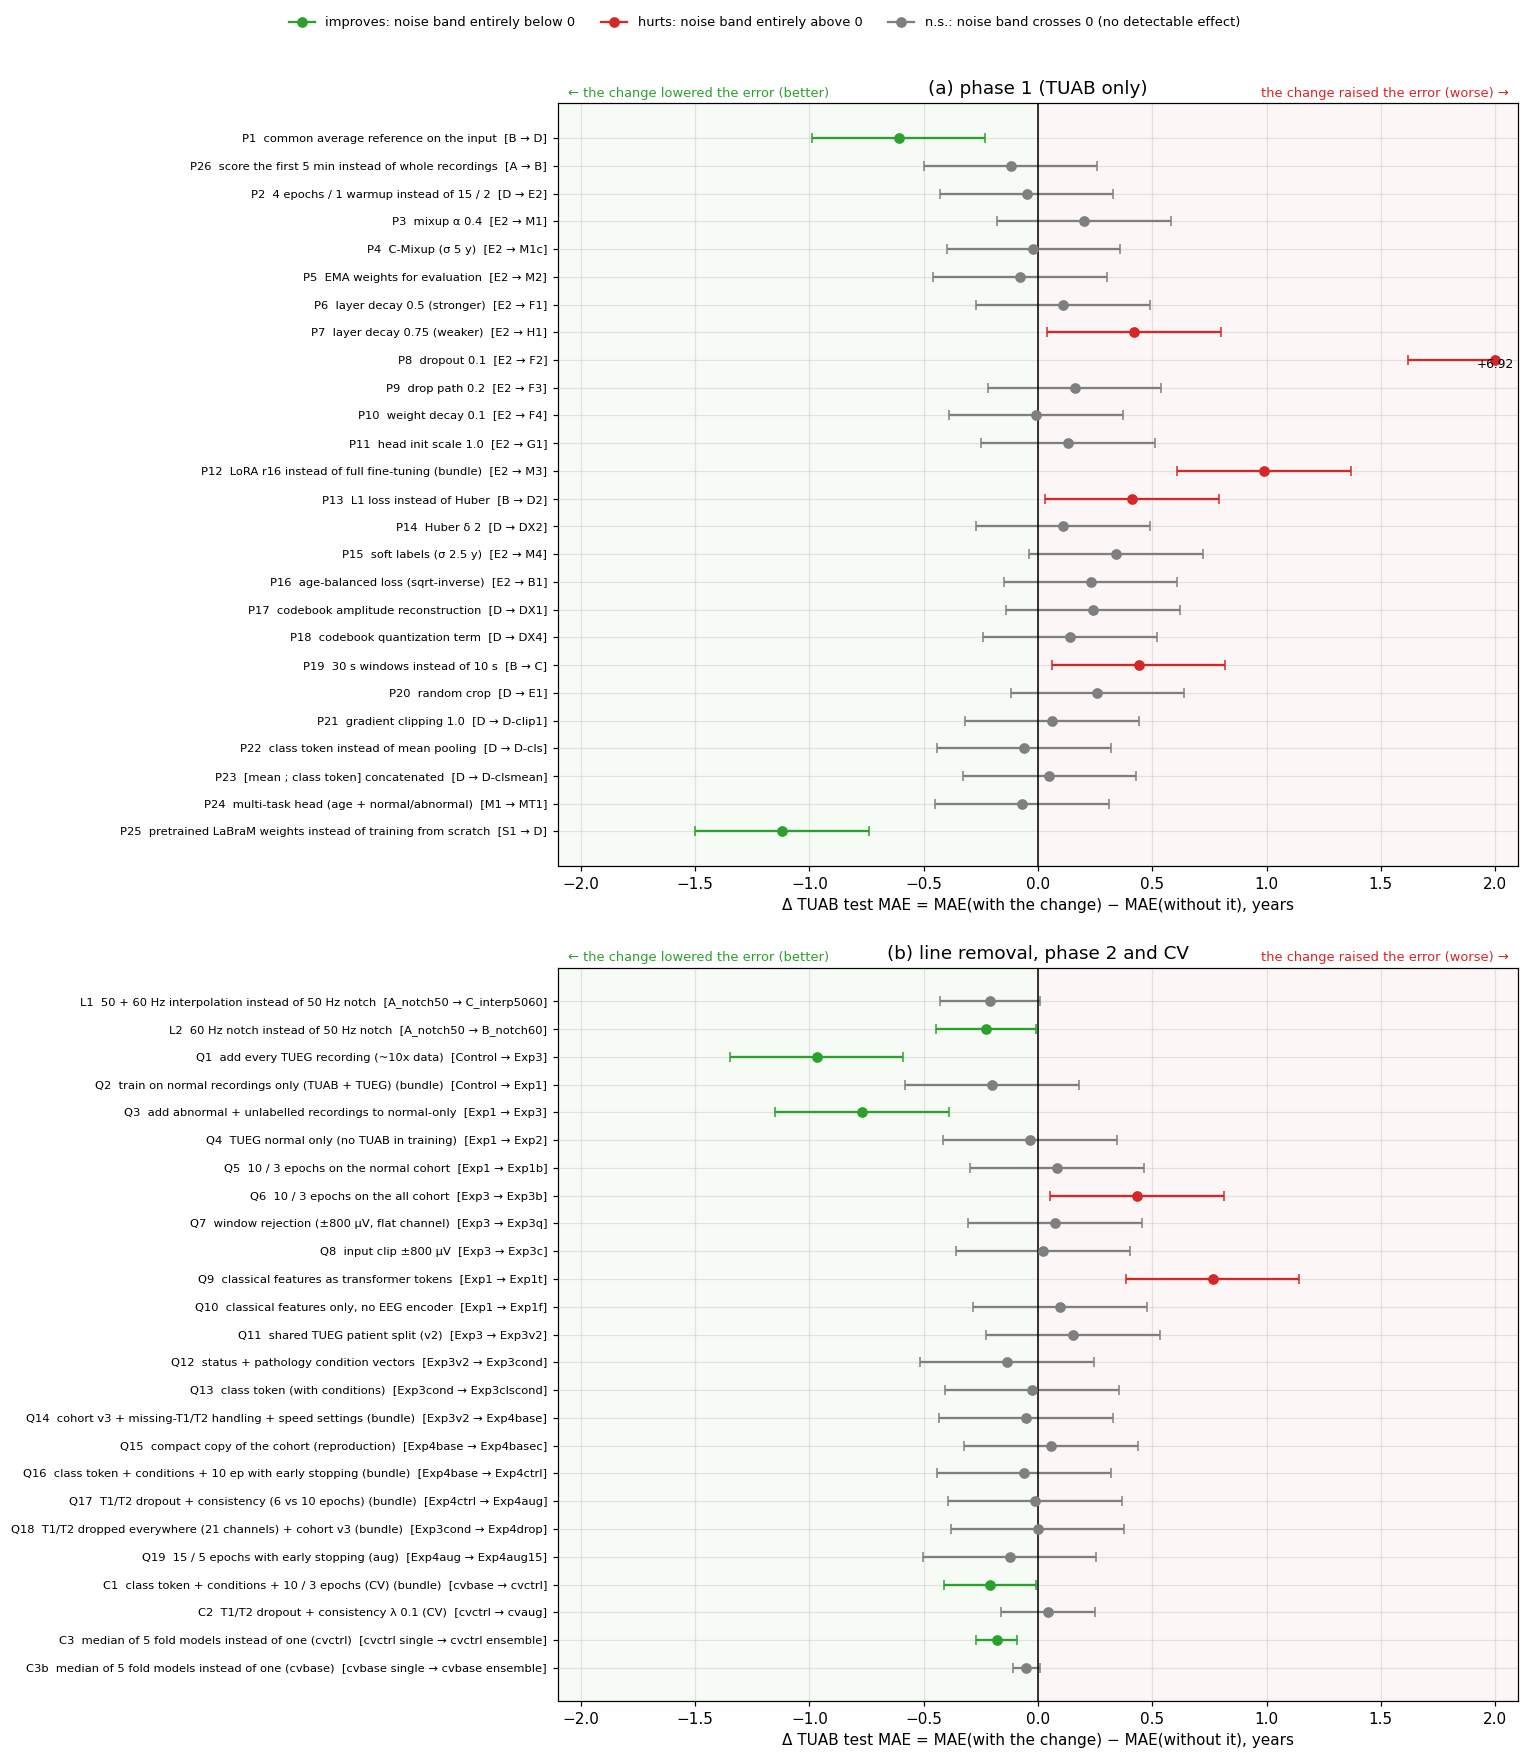

In [29]:
from matplotlib.lines import Line2D


def band(row):
    s = row["noise"]
    if isinstance(s, str) and s.startswith("["):
        lo, hi = (float(v) for v in s[1:s.index("]")].split(","))
        return row["Δ test"] - lo, hi - row["Δ test"]
    w = float(s.split()[-1]) if isinstance(s, str) and s.startswith("±") else 0.0
    return w, w


COL = {"improves": "tab:green", "hurts": "tab:red", "n.s.": "tab:gray", "–": "tab:gray"}
LIM = 2.0
fig, axes = plt.subplots(2, 1, figsize=(14, 16), gridspec_kw={"height_ratios": [26, 25]})
for ax, phases, title in ((axes[0], ("1",), "phase 1 (TUAB only)"), (axes[1], ("L", "2", "C"), "line removal, phase 2 and CV")):
    sub = t52[t52.phase.isin(phases) & t52["Δ test"].notna()]
    ax.axvspan(-LIM - 0.1, 0, color="tab:green", alpha=0.04)
    ax.axvspan(0, LIM + 0.1, color="tab:red", alpha=0.04)
    for y, (eid, row) in enumerate(sub.iterrows()):
        d = row["Δ test"]
        lo, hi = band(row)
        x = float(np.clip(d, -LIM, LIM))
        ax.errorbar(x, y, xerr=[[min(lo, x + LIM)], [min(hi, LIM - x)]], fmt="o", color=COL[row.verdict], capsize=3)
        if abs(d) > LIM:
            ax.text(x, y + 0.3, f"{d:+.2f}", fontsize=8, ha="center")
    ax.set_yticks(range(len(sub)), [f"{i}  {c}  [{bv}]" for i, c, bv in
                                    zip(sub.index, sub.change, sub["baseline → variant"])], fontsize=7.5)
    ax.invert_yaxis()
    ax.axvline(0, color="k", lw=1)
    ax.set_xlim(-LIM - 0.1, LIM + 0.1)
    ax.set_xlabel("Δ TUAB test MAE = MAE(with the change) − MAE(without it), years")
    ax.text(0.01, 1.005, "← the change lowered the error (better)", transform=ax.transAxes, ha="left",
            va="bottom", fontsize=8.5, color="tab:green")
    ax.text(0.99, 1.005, "the change raised the error (worse) →", transform=ax.transAxes, ha="right",
            va="bottom", fontsize=8.5, color="tab:red")
    ax.set_title(title, pad=16)
handles = [Line2D([], [], color=COL[v], marker="o", ls="-", label=lab) for v, lab in
           (("improves", "improves: noise band entirely below 0"), ("hurts", "hurts: noise band entirely above 0"),
            ("n.s.", "n.s.: noise band crosses 0 (no detectable effect)"))]
fig.legend(handles=handles, loc="upper center", ncol=3, fontsize=8.5, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.975))
panel_labels(axes)
assert_max_columns(fig)
plt.show()

### Table 5.3. Changes versus LaBraM: which mattered

The summary the study was after. One row per change from the LaBraM TUAB recipe to the best
configuration (Tables 4.1 and 4.2), with:
* `estimate`: the Table 5.2 row that isolates the change best and its $\Delta$ test;
* `verdict`: that row's verdict;
* `in best config`: whether the change is part of `cvctrl`.

`not isolated` means no run changes it alone, so its effect is not known.

In [30]:
SUMMARY = [
    ("training data: TUAB → TUAB + TUEG (~10x recordings)", "Q1", "yes"),
    ("abnormal and unlabelled recordings in training", "Q3", "yes"),
    ("pretrained LaBraM weights (vs from scratch)", "P25", "yes"),
    ("common average reference on the input", "P1", "yes"),
    ("mains: 50 + 60 Hz interpolation instead of 50 Hz notch", "L1", "yes"),
    ("ensemble: median of the 5 fold models", "C3", "yes"),
    ("class token + condition vectors + 10 epochs (bundle)", "C1", "yes"),
    ("condition vectors alone (single split)", "Q12", "yes"),
    ("class-token pooling alone (TUAB / TUH)", "P22", "yes"),
    ("short schedule (4–10 epochs instead of 15–50)", "P2", "yes"),
    ("mixup α 0.4", "P3", "yes"),
    ("cohort v3 + missing-T1/T2 handling + speed settings (bundle)", "Q14", "yes"),
    ("5-minute evaluation window", "P26", "yes"),
    ("T1/T2 channel-dropout augmentation", "C2", "no (cvaug)"),
    ("longer schedule on the full cohort (10 epochs)", "Q6", "no"),
    ("dropout 0.1", "P8", "no"),
    ("weaker layer decay 0.75", "P7", "no"),
    ("LoRA instead of full fine-tuning", "P12", "no"),
    ("30 s windows", "P19", "no"),
    ("classical features as tokens", "Q9", "no"),
    ("L1 loss", "P13", "no"),
    ("weight decay, drop path, layer decay 0.5, head init", "P10", "no"),
    ("loss shape: Huber δ 2, soft labels, age-balanced", "P16", "no"),
    ("codebook regularization", "P18", "no"),
    ("signal QC: window rejection / ±800 µV clip", "Q7", "no"),
    ("multi-task head", "P24", "no"),
    ("trim 60 s at both ends; lr 1e-4 (vs 5e-4); batch 128", None, "yes"),
]
rows = []
for change, eid, used in SUMMARY:
    if eid is None:
        rows.append({"change vs LaBraM": change, "estimate": "–", "Δ test": np.nan, "verdict": "not isolated",
                     "in best config": used})
        continue
    r = t52.loc[eid]
    rows.append({"change vs LaBraM": change, "estimate": f"{eid}: {r['baseline → variant']}", "Δ test": r["Δ test"],
                 "verdict": r["verdict"], "in best config": used})
t53 = pd.DataFrame(rows).set_index("change vs LaBraM")
numbered_table(t53, "5.3", "Changes versus LaBraM: which mattered")

,estimate,Δ test,verdict,in best config
change vs LaBraM,,,,
training data: TUAB → TUAB + TUEG (~10x recordings),Q1: Control → Exp3,-0.97,improves,yes
abnormal and unlabelled recordings in training,Q3: Exp1 → Exp3,-0.77,improves,yes
pretrained LaBraM weights (vs from scratch),P25: S1 → D,-1.12,improves,yes
common average reference on the input,P1: B → D,-0.61,improves,yes
mains: 50 + 60 Hz interpolation instead of 50 Hz notch,L1: A_notch50 → C_interp5060,-0.21,n.s.,yes
ensemble: median of the 5 fold models,C3: cvctrl single → cvctrl ensemble,-0.18,improves,yes
class token + condition vectors + 10 epochs (bundle),C1: cvbase → cvctrl,-0.21,improves,yes
condition vectors alone (single split),Q12: Exp3v2 → Exp3cond,-0.14,n.s.,yes
class-token pooling alone (TUAB / TUH),P22: D → D-cls,-0.06,n.s.,yes


## 6. Conclusions

Generated from the tables above, so they stay in step with the data when the notebook is re-run.

In [31]:
v = t52.verdict
imp, hurt = t52[v == "improves"], t52[v == "hurts"]
m = lambda exp, c="all": fold_stats(exp, "heldout", "TUAB", c)
lines = [
    f"* **Noise floor.** Seed-to-seed sd of the TUAB test MAE is {SD['test_mae']:.2f} years (Table 5.1), so two "
    f"single runs must differ by more than {TAU:.2f} years to count (Eq. (5.2)). Of {len(t52)} tested changes, "
    f"{len(imp)} improve, {len(hurt)} hurt and {int((v == 'n.s.').sum())} are within noise (Table 5.2).",
    "* **What improved the error (Table 5.2):** " + "; ".join(
        f"{i} {r.change} ({r['Δ test']:+.2f})" for i, r in imp.sort_values("Δ test").iterrows()) + ".",
    "* **What hurt:** " + "; ".join(f"{i} {r.change} ({r['Δ test']:+.2f})" for i, r in hurt.sort_values("Δ test").iterrows()) + ".",
    f"* **Best configuration: `cvctrl`.** TUAB test MAE {m('cvctrl')[0]:.2f} ± {m('cvctrl')[1]:.2f} per fold model "
    f"(normal {m('cvctrl', 'normal')[0]:.2f}, abnormal {m('cvctrl', 'abnormal')[0]:.2f}; Table 3.3). Its head is given "
    "the status/pathology vector.",
    f"* **Best EEG-only: `cvbase`.** {m('cvbase')[0]:.2f} ± {m('cvbase')[1]:.2f} per fold model, normal recordings "
    f"{m('cvbase', 'normal')[0]:.2f}, against 6.60 for the best published TUAB normal result (Gemein et al. 2024, "
    "different split and training data).",
]
if preds is not None and STATUS:
    lines.append(f"* **Ensembles.** The median of the 5 fold models scores {ens_mae('cvctrl'):.2f} (`cvctrl`) and "
                 f"{ens_mae('cvbase'):.2f} (`cvbase`) on the TUAB test, normal {ens_mae('cvbase', 'normal'):.2f} (`cvbase`).")
lines += [
    "* **Most of the gain over LaBraM comes from data.** The largest effects are:",
    "  * more and more varied training recordings (Q1, Q3);",
    "  * pretrained weights (P25);",
    "  * the common average reference (P1).",
    "  Architecture, loss and regularization changes are within noise or harmful (Table 5.3).",
    "* **The abnormal cohort carries the error.** Abnormal recordings stay about 4 years worse than normal "
    "ones in every configuration (Tables 2.3, 3.3).",
]
display(Markdown("\n".join(lines)))

* **Noise floor.** Seed-to-seed sd of the TUAB test MAE is 0.14 years (Table 5.1), so two single runs must differ by more than 0.38 years to count (Eq. (5.2)). Of 51 tested changes, 7 improve, 7 hurt and 37 are within noise (Table 5.2).
* **What improved the error (Table 5.2):** P25 pretrained LaBraM weights instead of training from scratch (-1.12); Q1 add every TUEG recording (~10x data) (-0.97); Q3 add abnormal + unlabelled recordings to normal-only (-0.77); P1 common average reference on the input (-0.61); L2 60 Hz notch instead of 50 Hz notch (-0.23); C1 class token + conditions + 10 / 3 epochs (CV) (bundle) (-0.21); C3 median of 5 fold models instead of one (cvctrl) (-0.18).
* **What hurt:** P13 L1 loss instead of Huber (+0.41); P7 layer decay 0.75 (weaker) (+0.42); Q6 10 / 3 epochs on the all cohort (+0.43); P19 30 s windows instead of 10 s (+0.44); Q9 classical features as transformer tokens (+0.76); P12 LoRA r16 instead of full fine-tuning (bundle) (+0.99); P8 dropout 0.1 (+6.92).
* **Best configuration: `cvctrl`.** TUAB test MAE 7.28 ± 0.14 per fold model (normal 5.53, abnormal 9.37; Table 3.3). Its head is given the status/pathology vector.
* **Best EEG-only: `cvbase`.** 7.49 ± 0.09 per fold model, normal recordings 5.81, against 6.60 for the best published TUAB normal result (Gemein et al. 2024, different split and training data).
* **Ensembles.** The median of the 5 fold models scores 7.10 (`cvctrl`) and 7.44 (`cvbase`) on the TUAB test, normal 5.75 (`cvbase`).
* **Most of the gain over LaBraM comes from data.** The largest effects are:
  * more and more varied training recordings (Q1, Q3);
  * pretrained weights (P25);
  * the common average reference (P1).
  Architecture, loss and regularization changes are within noise or harmful (Table 5.3).
* **The abnormal cohort carries the error.** Abnormal recordings stay about 4 years worse than normal ones in every configuration (Tables 2.3, 3.3).

**Caveats.**
* **Selection on test:** phases 1 and 2 chose among configurations on the TUAB test set, so their best
  single-split numbers are optimistic. The CV and TUEG out-of-fold numbers are not.
* **Bundles:** C1, Q14, Q16, Q17 and Q18 change several things at once, so their parts are not
  separately known.
* **Condition vectors:** `cvctrl` and `cvaug` use the status/pathology vector at test time. Only `cvbase`
  is comparable with EEG-only brain-age models.
* **Noise floor scope:** it comes from one configuration, the E2 recipe on TUAB (Table 5.1), and is assumed to transfer
  to the larger cohorts.